# Импорт библиотек

In [1]:
%pip install scikit-learn xgboost openpyxl pandas numpy matplotlib catboost optuna


[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: /opt/homebrew/opt/python@3.11/bin/python3.11 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [ ]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split, RandomizedSearchCV, learning_curve, KFold, RepeatedKFold, cross_validate, cross_val_predict, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor, VotingRegressor
from sklearn.linear_model import RidgeCV, LassoCV, ElasticNetCV
from sklearn.linear_model import Ridge, Lasso, ElasticNet
from sklearn.metrics import r2_score, mean_absolute_error
from sklearn.feature_selection import RFECV, RFE
from sklearn.inspection import permutation_importance
from sklearn.pipeline import Pipeline
from catboost import CatBoostRegressor
from sklearn.tree import DecisionTreeRegressor
import xgboost as xgb
import optuna
import optuna.visualization as vis
from sklearn.model_selection import cross_val_score
from sklearn.base import clone
from sklearn.neural_network import MLPRegressor
from scipy.stats import linregress


file_path = r"/Users/artemykagramanian/Desktop/ампермагнит/MCE + ML/обработанные датасеты/magnetocaloric_perovskites_full_descriptors.xlsx"
out_dir = r"DCD_paper"

# Оформление графиков

In [3]:
# Константы для оформления графиков
CM_TO_INCH = 1 / 2.54
COLUMN_WIDTH = 8.5 * CM_TO_INCH

plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "DejaVu Serif"],
    "mathtext.fontset": "stix",

    "font.size": 9,
    "axes.labelsize": 10,
    "axes.titlesize": 10,
    "xtick.labelsize": 8.5,
    "ytick.labelsize": 8.5,
    "legend.fontsize": 8.5,

    "axes.linewidth": 0.9,
    "xtick.major.width": 0.8,
    "ytick.major.width": 0.8,
    "xtick.major.size": 3.5,
    "ytick.major.size": 3.5,

    "figure.dpi": 300,
    "savefig.dpi": 600,
    "savefig.bbox": "tight",
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

COLORS = {
    "blue": "#1f4e79",
    "red": "#b22222",
    "green": "#2e7d32",
    "gray": "#666666",
    "black": "#000000",
}

FEATURE_MAP = {
    'H_ex (T)': r'$H_{\mathrm{ex}}$ (T)',
    'min:mendeleev_number': r'$N_{\mathrm{Mend, min}}$',
    'max:melting_point': r'$T_{\mathrm{m, max}}$',
    'max:density': r'$\rho_{\max}$',
    'max:hhi_r': r'$\mathrm{HHI}_{\mathrm{res, max}}$'
}

if "format_axes" not in globals():
    def format_axes(ax, grid=True):
        ax.tick_params(direction="in", top=True, right=True)
        if grid:
            ax.grid(True, linestyle="--", linewidth=0.45, alpha=0.35)
        for spine in ax.spines.values():
            spine.set_linewidth(0.9)

if "save_figure" not in globals():
    def save_figure(fig, name):
        fig.savefig(os.path.join(out_dir, f"{name}.png"), dpi=600)


# --- перевод "sum:atomic_number" и т.п. в LaTeX-подписи ---
PREFIX_LATEX = {
    "sum": r"\Sigma",
    "ave": r"\langle X \rangle",
    "var": r"\mathrm{Var}",
    "max": r"\mathrm{Max}",
    "min": r"\mathrm{Min}",
    "geo": r"\mathrm{Geo}",
    "har": r"\mathrm{Har}",
    "mindelta": r"\mathrm{Min}\Delta",
    "tolf": r"\mathrm{TolF}",
}

PROPERTY_LATEX = {
    "atomic_number": "Z",
    "atomic_radius": "r_{at}",
    "atomic_radius_rahm": "r_{Rahm}",
    "atomic_volume": "V_{at}",
    "atomic_weight": "M_{at}",
    "electron_affinity": "E_{EA}",
    "electronegativity": r"\chi",
    "en_pauling": r"\chi_{P}",
    "en_allen": r"\chi_{A}",
    "melting_point": "T_{melt}",
    "boiling_point": "T_{boil}",
    "density": r"\rho",
    "heat_capacity_molar": "C_{p,molar}",
    "thermal_conductivity": r"\kappa",
    "lattice_constant": "a_{lat}",
    "bulk_modulus": "K",
    "molar_volume": "V_{molar}",
    "num_f_unfilled": "n_{f}^{unfilled}",
    "num_d_unfilled": "n_{d}^{unfilled}",
    "num_valence": "n_{val}",
    "hhi_r": "HHI_{R}",
    "hhi_p": "HHI_{P}",
    "covalent_radius_cordero": "r_{cov}^{Cordero}",
    "covalent_radius_slater": "r_{cov}^{Slater}",
    "covalent_radius_pyykko": "r_{cov}^{Pyykko}",
    "vdw_radius_alvarez": "r_{vdW}",
    "sound_velocity": "v_{sound}",
    "evaporation_heat": r"\Delta H_{evap}",
    "fusion_enthalpy": r"\Delta H_{fus}",
    "heat_of_formation": r"\Delta H_{f}",
    "mendeleev_number": "N_{Mendeleev}",
    "specific_heat": "c_{p}",
}

def save_figure(fig, name):
    fig.savefig(os.path.join(out_dir, f"{name}.png"), dpi=600)


def save_figure_to(fig, name, folder):
    fig.savefig(os.path.join(folder, f"{name}.png"), dpi=600)


def format_axes(ax, grid=True):
    ax.tick_params(direction="in", top=True, right=True)

    if grid:
        ax.grid(True, linestyle="--", linewidth=0.45, alpha=0.35)

    for spine in ax.spines.values():
        spine.set_linewidth(0.9)

# Функции построения графиков

In [22]:
# --- обёртка над MLPRegressor, чтобы RFE могло ранжировать по ней признаки ---
class MLPRegressorRFE(MLPRegressor):
    @property
    def coef_(self):
        # норма весов первого слоя по каждому входному признаку — прокси важности
        return np.linalg.norm(self.coefs_[0], axis=1)

def plot_delta_s_histogram(delta_s):
    fig, ax = plt.subplots(figsize=(COLUMN_WIDTH, COLUMN_WIDTH * 0.72))

    ax.hist(
        delta_s,
        bins=22,
        color=COLORS["blue"],
        edgecolor=COLORS["black"],
        linewidth=0.45,
        alpha=0.88
    )

    ax.axvline(delta_s.mean(), color=COLORS["red"], linestyle="--",
               linewidth=1.1, label="Mean")
    ax.axvline(delta_s.median(), color=COLORS["black"], linestyle="-",
               linewidth=1.1, label="Median")

    ax.set_xlabel(r"$\Delta S_M$ (J kg$^{-1}$ K$^{-1}$)")
    ax.set_ylabel("Frequency")
    ax.set_title(r"Distribution of $\Delta S_M$")

    ax.legend(frameon=True, edgecolor="black", framealpha=1.0)
    format_axes(ax)

    fig.tight_layout(pad=0.4)
    save_figure(fig, "Fig1_delta_S_histogram")
    plt.show()


def plot_transformation_histogram(y_original):
    y_log = np.log1p(y_original)

    fig, ax = plt.subplots(figsize=(COLUMN_WIDTH, COLUMN_WIDTH * 0.72))

    ax.hist(
        y_original,
        bins=22,
        color=COLORS["blue"],
        edgecolor=COLORS["black"],
        linewidth=0.45,
        alpha=0.88
    )

    ax.set_xlabel(r"$\Delta S_M$ (J kg$^{-1}$ K$^{-1}$)")
    ax.set_ylabel("Frequency")
    ax.set_title(r"Original $\Delta S_M$ distribution")

    format_axes(ax)
    fig.tight_layout(pad=0.4)
    save_figure(fig, "Fig2_original_distribution")
    plt.show()

    fig, ax = plt.subplots(figsize=(COLUMN_WIDTH, COLUMN_WIDTH * 0.72))

    ax.hist(
        y_log,
        bins=22,
        color=COLORS["green"],
        edgecolor=COLORS["black"],
        linewidth=0.45,
        alpha=0.88
    )

    ax.set_xlabel(r"$\log(1+\Delta S_M)$")
    ax.set_ylabel("Frequency")
    ax.set_title(r"Log-transformed distribution")

    format_axes(ax)
    fig.tight_layout(pad=0.4)
    save_figure(fig, "Fig3_log_distribution")
    plt.show()


def plot_rfecv_curve(rfecv, optimal_k):
    if rfecv is None:
        print("RFECV plot skipped: RFECV was not performed.")
        return

    mean_scores = rfecv.cv_results_["mean_test_score"]
    n_features = np.arange(1, len(mean_scores) + 1)

    fig, ax = plt.subplots(figsize=(COLUMN_WIDTH, COLUMN_WIDTH * 0.72))

    ax.plot(
        n_features,
        mean_scores,
        marker="o",
        markersize=3.2,
        linewidth=1.2,
        color=COLORS["blue"],
        label=r"Mean CV $R^2$"
    )

    ax.axvline(
        optimal_k,
        color=COLORS["red"],
        linestyle="--",
        linewidth=1.1,
        label=f"Optimal: {optimal_k}"
    )

    ax.set_xlabel("Number of selected features")
    ax.set_ylabel(r"Cross-validation $R^2$")
    ax.set_title("RFECV feature selection")

    ax.legend(frameon=True, edgecolor="black", framealpha=1.0)
    format_axes(ax)

    fig.tight_layout(pad=0.4)
    save_figure(fig, "Fig4_rfecv_curve")
    plt.show()


def feature_to_latex(feature_name):
    if ":" not in feature_name:
        return feature_name.replace("_", r"\_")

    prefix, prop = feature_name.split(":", 1)
    prefix = prefix.lower()

    prop_sym = PROPERTY_LATEX.get(prop.lower(), None)
    if prop_sym is None:
        prop_readable = prop.replace("_", r"\ ").title()
        prop_sym = rf"\mathrm{{{prop_readable}}}"

    if prefix == "ave":
        return rf"$\langle {prop_sym} \rangle$"  # скобки вокруг самого признака, без "X"

    if prefix == "var":
        return rf"$\mathrm{{Var}}({prop_sym})$"  # Var(...) вместо "Var ..."

    prefix_sym = PREFIX_LATEX.get(prefix, rf"\mathrm{{{prefix}}}")
    return rf"${prefix_sym}\ {prop_sym}$"

def plot_feature_importance_paper(imp_df, top_n=None, model_name="CatBoost", orientation="horizontal"):
    imp = imp_df.copy()

    if top_n is not None:
        imp = imp.sort_values("rf_importance", ascending=True).tail(top_n)
    else:
        imp = imp.sort_values("rf_importance", ascending=True)

    imp["feature_display"] = imp["feature"].apply(feature_to_latex)
    n_feat = len(imp)
    safe_name = model_name.lower().replace(" ", "_")

    if orientation == "vertical":
        imp_sorted = imp.sort_values("rf_importance", ascending=False)

        fig, ax = plt.subplots(figsize=(max(COLUMN_WIDTH * 2.2, n_feat * 0.32), COLUMN_WIDTH * 1.1))

        ax.bar(
            imp_sorted["feature_display"],
            imp_sorted["rf_importance"],
            color=COLORS["blue"],
            edgecolor=COLORS["black"],
            linewidth=0.45,
            width=0.7
        )

        ax.set_xticks(range(n_feat))
        ax.set_xticklabels(imp_sorted["feature_display"], rotation=90, ha="center", fontsize=7)
        ax.set_ylabel("Feature importance")
        ax.set_xlabel("Descriptor")

    else:
        fig, ax = plt.subplots(figsize=(COLUMN_WIDTH, COLUMN_WIDTH * 1.35))

        bars = ax.barh(
            imp["feature_display"],
            imp["rf_importance"],
            color=COLORS["blue"],
            edgecolor=COLORS["black"],
            linewidth=0.45,
            height=0.68
        )

        xmax = imp["rf_importance"].max()
        ax.set_xlim(0, xmax * 1.28)

        for bar, value in zip(bars, imp["rf_importance"]):
            ax.text(
                value + xmax * 0.025,
                bar.get_y() + bar.get_height() / 2,
                f"{value:.3f}",
                va="center", ha="left", fontsize=7.5
            )

        ax.set_xlabel("Feature importance")
        ax.set_ylabel("Descriptor")

    ax.set_title(f"{model_name}: feature importance")
    format_axes(ax)
    fig.tight_layout(pad=0.4 if orientation == "horizontal" else 0.35)
    save_figure(fig, f"Fig_feature_importance_{safe_name}_{orientation}")
    plt.show()

def plot_model_comparison(results_df):
    res = results_df.sort_values("R2_transformed", ascending=True)

    fig, ax = plt.subplots(figsize=(COLUMN_WIDTH, COLUMN_WIDTH * 0.85))

    bars = ax.barh(
        res["Model"],
        res["R2_transformed"],
        color=COLORS["blue"],
        edgecolor=COLORS["black"],
        linewidth=0.45,
        height=0.68
    )

    xmax = max(res["R2_transformed"].max(), 0.1)
    ax.set_xlim(0, xmax * 1.25)

    for bar, value in zip(bars, res["R2_transformed"]):
        ax.text(
            value + xmax * 0.025,
            bar.get_y() + bar.get_height() / 2,
            f"{value:.3f}",
            va="center",
            ha="left",
            fontsize=7.5
        )

    ax.set_xlabel(r"$R^2$")
    ax.set_ylabel("Model")
    ax.set_title("Model performance")

    format_axes(ax)
    fig.tight_layout(pad=0.35)
    save_figure(fig, "Fig6_model_comparison")
    plt.show()


def plot_parity(y_true, y_pred, name="rf"):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    r2 = r2_score(y_true, y_pred)
    mae = mean_absolute_error(y_true, y_pred)

    min_val = min(y_true.min(), y_pred.min())
    max_val = max(y_true.max(), y_pred.max())
    margin = 0.07 * (max_val - min_val)

    fig, ax = plt.subplots(figsize=(COLUMN_WIDTH, COLUMN_WIDTH))

    ax.scatter(
        y_true,
        y_pred,
        s=22,
        color=COLORS["green"],
        edgecolor=COLORS["black"],
        linewidth=0.35,
        alpha=0.78
    )

    ax.plot(
        [min_val - margin, max_val + margin],
        [min_val - margin, max_val + margin],
        linestyle="--",
        linewidth=1.1,
        color=COLORS["red"],
        label="Ideal"
    )

    ax.text(
        0.06,
        0.94,
        rf"$R^2$ = {r2:.3f}" + "\n" +
        rf"MAE = {mae:.2f}",
        transform=ax.transAxes,
        va="top",
        ha="left",
        fontsize=8.5,
        bbox=dict(
            boxstyle="round,pad=0.25",
            facecolor="white",
            edgecolor="black",
            linewidth=0.6,
            alpha=0.92
        )
    )

    ax.set_xlabel(r"Experimental $\Delta S_M$" + "\n" + r"(J kg$^{-1}$ K$^{-1}$)")
    ax.set_ylabel(r"Predicted $\Delta S_M$" + "\n" + r"(J kg$^{-1}$ K$^{-1}$)")
    ax.set_title(r"Experimental vs predicted $\Delta S_M$")

    ax.set_xlim(min_val - margin, max_val + margin)
    ax.set_ylim(min_val - margin, max_val + margin)
    ax.set_aspect("equal", adjustable="box")

    ax.legend(frameon=True, edgecolor="black", framealpha=1.0, loc="lower right")
    format_axes(ax)

    fig.tight_layout(pad=0.35)
    save_figure(fig, f"Fig7_parity_plot_{name}")
    plt.show()


def plot_residuals(y_true, y_pred, name="rf"):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    residuals = y_pred - y_true

    fig, ax = plt.subplots(figsize=(COLUMN_WIDTH, COLUMN_WIDTH * 0.72))

    ax.axhline(0, color=COLORS["black"], linewidth=0.9)

    ax.scatter(
        y_true,
        residuals,
        s=22,
        color=COLORS["blue"],
        edgecolor=COLORS["black"],
        linewidth=0.35,
        alpha=0.78
    )

    ax.set_xlabel(r"Experimental $\Delta S_M$" + "\n" + r"(J kg$^{-1}$ K$^{-1}$)")
    ax.set_ylabel("Residual")
    ax.set_title("Residual analysis")

    format_axes(ax)
    fig.tight_layout(pad=0.35)
    save_figure(fig, f"Fig8_residuals_{name}")
    plt.show()


def plot_learning_curve(train_sizes_abs, train_mean, test_mean, train_std, test_std):
    fig, ax = plt.subplots(figsize=(COLUMN_WIDTH, COLUMN_WIDTH * 0.72))

    ax.plot(
        train_sizes_abs,
        train_mean,
        marker="o",
        markersize=3.2,
        linewidth=1.2,
        color=COLORS["blue"],
        label="Training"
    )

    ax.plot(
        train_sizes_abs,
        test_mean,
        marker="s",
        markersize=3.2,
        linewidth=1.2,
        color=COLORS["red"],
        label="CV"
    )

    ax.fill_between(
        train_sizes_abs,
        train_mean - train_std,
        train_mean + train_std,
        color=COLORS["blue"],
        alpha=0.15,
        linewidth=0
    )

    ax.fill_between(
        train_sizes_abs,
        test_mean - test_std,
        test_mean + test_std,
        color=COLORS["red"],
        alpha=0.15,
        linewidth=0
    )

    ax.set_xlabel("Training set size")
    ax.set_ylabel(r"$R^2$")
    ax.set_title("Learning curve")

    ax.set_ylim(0.0, 1.05)
    ax.legend(frameon=True, edgecolor="black", framealpha=1.0)
    format_axes(ax)

    fig.tight_layout(pad=0.35)
    save_figure(fig, "Fig9_learning_curve_rf")
    plt.show()


def compute_permutation_importance(model, X_test, y_test, feature_names,
                                    n_repeats=50, random_state=42):
    perm = permutation_importance(
        model, X_test, y_test,
        n_repeats=n_repeats,
        random_state=random_state,
        scoring="r2",
        n_jobs=-1
    )
    perm_df = pd.DataFrame({
        "feature": feature_names,
        "perm_importance_mean": perm.importances_mean,
        "perm_importance_std": perm.importances_std
    }).sort_values("perm_importance_mean", ascending=False)
    return perm_df


def plot_permutation_importance(perm_df, top_n=12):
    imp = perm_df.sort_values("perm_importance_mean", ascending=True).tail(top_n)

    fig, ax = plt.subplots(figsize=(COLUMN_WIDTH, COLUMN_WIDTH * 1.35))

    bars = ax.barh(
        imp["feature"],
        imp["perm_importance_mean"],
        xerr=imp["perm_importance_std"],
        color=COLORS["blue"],
        edgecolor=COLORS["black"],
        linewidth=0.45,
        height=0.68,
        capsize=2.5,
        error_kw={"linewidth": 0.8, "ecolor": COLORS["gray"]}
    )

    xmax = (imp["perm_importance_mean"] + imp["perm_importance_std"]).max()
    xmin = min(0, (imp["perm_importance_mean"] - imp["perm_importance_std"]).min())
    ax.set_xlim(xmin * 1.1 if xmin < 0 else 0, xmax * 1.3)

    for bar, value in zip(bars, imp["perm_importance_mean"]):
        ax.text(
            value + xmax * 0.03,
            bar.get_y() + bar.get_height() / 2,
            f"{value:.3f}",
            va="center",
            ha="left",
            fontsize=7.5
        )

    ax.axvline(0, color=COLORS["black"], linewidth=0.7)
    ax.set_xlabel(r"Permutation importance ($\Delta R^2$, test set)")
    ax.set_ylabel("Descriptor")
    ax.set_title("Random Forest permutation importance")

    format_axes(ax)
    fig.tight_layout(pad=0.35)
    save_figure(fig, "Fig5_feature_importance_rf_permutation")
    plt.show()


def select_one_se_features(rfecv, min_features_to_select=1):
    cv_results = rfecv.cv_results_
    mean_scores = np.asarray(cv_results["mean_test_score"])
    std_scores = np.asarray(cv_results["std_test_score"])
    n_features = np.arange(min_features_to_select,
                            min_features_to_select + len(mean_scores))

    n_splits = rfecv.cv if isinstance(rfecv.cv, int) else 5
    se_scores = std_scores / np.sqrt(n_splits)

    best_idx = int(np.argmax(mean_scores))
    best_score = mean_scores[best_idx]
    best_se = se_scores[best_idx]
    threshold = best_score - best_se

    candidates = np.where(mean_scores >= threshold)[0]
    one_se_idx = int(candidates.min())

    return {
        "n_features": n_features,
        "mean_scores": mean_scores,
        "se_scores": se_scores,
        "best_idx": best_idx,
        "best_n": n_features[best_idx],
        "one_se_idx": one_se_idx,
        "one_se_n": n_features[one_se_idx],
        "threshold": threshold,
    }


def plot_rfecv_curve_one_se(rfecv, min_features_to_select=1):
    if rfecv is None:
        print("RFECV plot skipped: RFECV was not performed.")
        return None

    stats = select_one_se_features(rfecv, min_features_to_select)

    fig, ax = plt.subplots(figsize=(COLUMN_WIDTH, COLUMN_WIDTH * 0.72))

    ax.plot(
        stats["n_features"],
        stats["mean_scores"],
        marker="o",
        markersize=2.6,
        linewidth=1.0,
        color=COLORS["blue"],
        label=r"Mean CV $R^2$"
    )

    ax.fill_between(
        stats["n_features"],
        stats["mean_scores"] - stats["se_scores"],
        stats["mean_scores"] + stats["se_scores"],
        color=COLORS["blue"],
        alpha=0.15,
        linewidth=0
    )

    ax.axhline(
        stats["threshold"],
        color=COLORS["gray"],
        linestyle=":",
        linewidth=1.0,
        label="Best score - 1 SE"
    )

    ax.axvline(
        stats["best_n"],
        color=COLORS["green"],
        linestyle="--",
        linewidth=1.0,
        label=f"Max score: {stats['best_n']}"
    )

    ax.axvline(
        stats["one_se_n"],
        color=COLORS["red"],
        linestyle="--",
        linewidth=1.2,
        label=f"1-SE optimal: {stats['one_se_n']}"
    )

    ax.set_xlabel("Number of selected features")
    ax.set_ylabel(r"Cross-validation $R^2$")
    ax.set_title("RFECV feature selection (1-SE rule)")

    ax.legend(frameon=True, edgecolor="black", framealpha=1.0, fontsize=7)
    format_axes(ax)

    fig.tight_layout(pad=0.4)
    save_figure(fig, "Fig4_rfecv_curve_one_se")
    plt.show()

    print(f"Best mean CV R^2 = {stats['mean_scores'][stats['best_idx']]:.4f} "
          f"at {stats['best_n']} features")
    print(f"1-SE rule selects {stats['one_se_n']} features "
          f"(threshold = {stats['threshold']:.4f})")

    return stats


def compute_all_models_importance(models, X_test, y_test, feature_names,
                                   n_repeats=50, random_state=42):
    importance_matrix = pd.DataFrame(index=feature_names)

    for name, model in models.items():
        perm = permutation_importance(
            model, X_test, y_test,
            n_repeats=n_repeats,
            random_state=random_state,
            scoring="r2",
            n_jobs=-1
        )
        importance_matrix[name] = perm.importances_mean

    return importance_matrix


def compute_all_models_native_importance(models, feature_names):
    native_matrix = pd.DataFrame(index=feature_names)

    for name, model in models.items():
        if hasattr(model, "feature_importances_"):
            native_matrix[name] = model.feature_importances_
        elif hasattr(model, "coef_"):
            native_matrix[name] = np.abs(np.ravel(model.coef_))
        elif hasattr(model, "estimators_"):
            sub_importances = [
                est.feature_importances_ for est in model.estimators_
                if hasattr(est, "feature_importances_")
            ]
            if sub_importances:
                native_matrix[name] = np.mean(sub_importances, axis=0)
            else:
                print(f"Skipping '{name}': no native importance available.")
        else:
            print(f"Skipping '{name}': no native importance available.")

    return native_matrix


def plot_single_model_importance(importance_series, model_name, method_label,
                                  save_dir, top_n=12, xlabel=None):
    imp = importance_series.sort_values(ascending=True).tail(top_n)

    fig, ax = plt.subplots(figsize=(COLUMN_WIDTH, COLUMN_WIDTH * 1.1))

    bars = ax.barh(
        imp.index,
        imp.values,
        color=COLORS["blue"],
        edgecolor=COLORS["black"],
        linewidth=0.45,
        height=0.68
    )

    xmax = imp.values.max()
    xmin = min(0, imp.values.min())
    ax.set_xlim(xmin * 1.1 if xmin < 0 else 0, xmax * 1.3)

    for bar, value in zip(bars, imp.values):
        ax.text(
            value + xmax * 0.03,
            bar.get_y() + bar.get_height() / 2,
            f"{value:.3f}",
            va="center",
            ha="left",
            fontsize=7.5
        )

    ax.axvline(0, color=COLORS["black"], linewidth=0.7)
    ax.set_xlabel(xlabel or method_label)
    ax.set_ylabel("Descriptor")
    ax.set_title(f"{model_name}: {method_label}")

    format_axes(ax)
    fig.tight_layout(pad=0.35)

    safe_model = model_name.lower().replace(" ", "_")
    safe_method = method_label.lower().replace(" ", "_")
    save_figure_to(fig, f"{safe_method}_{safe_model}", save_dir)
    plt.show()


def remove_outliers_2_5_sigma(y_true, y_pred, formulas=None, out_dir="."):
    # Принудительно выравниваем массивы в 1D векторы
    y_true = np.ravel(y_true)
    y_pred = np.ravel(y_pred)

    # Остатки
    residuals = y_pred - y_true

    # Стандартное отклонение (с ddof=0, как по умолчанию в numpy.std)
    std = residuals.std()
    threshold = 2.5 * std

    is_outlier = np.abs(residuals) > threshold
    clean_mask = ~is_outlier  # Маска "чистых" данных

    r2_before = r2_score(y_true, y_pred)
    mae_before = mean_absolute_error(y_true, y_pred)
    r2_after = r2_score(y_true[clean_mask], y_pred[clean_mask])
    mae_after = mean_absolute_error(y_true[clean_mask], y_pred[clean_mask])

    print(f"\n--- Outlier removal (|error| > 2.5 sigma), Random Forest ---")
    print(f"Residual std = {std:.4f}, threshold = {threshold:.4f}")
    print(f"Removed {is_outlier.sum()} of {len(y_true)} points "
          f"({100 * is_outlier.sum() / len(y_true):.1f}%)")
    print(f"R2  before: {r2_before:.3f}  ->  after: {r2_after:.3f}")
    print(f"MAE before: {mae_before:.3f}  ->  after: {mae_after:.3f}")

    # Корректная фильтрация формул
    if formulas is not None:
        formulas_arr = np.ravel(formulas)
        outlier_formulas = formulas_arr[is_outlier]
    else:
        outlier_formulas = np.where(is_outlier)[0]

    outliers_df = pd.DataFrame({
        "formula": outlier_formulas,
        "y_true": y_true[is_outlier],
        "y_pred": y_pred[is_outlier],
        "residual": residuals[is_outlier]
    }).sort_values("residual", key=np.abs, ascending=False)

    # Сохраняем в Excel
    out_path = os.path.join(out_dir, "outliers_removed_2_5_sigma_random_forest.xlsx")
    outliers_df.to_excel(out_path, index=False)
    print(f"Excluded points saved to {out_path}")

    # Возвращаем словарь со ВСЕМИ возможными именами ключей для маски
    return {
        "clean_mask": clean_mask,
        "keep_mask": clean_mask,
        "is_outlier": is_outlier,
        "r2_before": r2_before,
        "r2_after": r2_after,
        "mae_before": mae_before,
        "mae_after": mae_after,
        "outliers_df": outliers_df
    }

def build_model_from_trial(model_name, trial):
    if model_name == "Ridge":
        alpha = trial.suggest_float("alpha", 1e-3, 1e3, log=True)
        return Ridge(alpha=alpha)

    if model_name == "Lasso":
        alpha = trial.suggest_float("alpha", 1e-6, 1.0, log=True)
        return Lasso(alpha=alpha, max_iter=10000)

    if model_name == "ElasticNet":
        alpha = trial.suggest_float("alpha", 1e-5, 1.0, log=True)
        l1_ratio = trial.suggest_float("l1_ratio", 0.005, 1.0)
        return ElasticNet(alpha=alpha, l1_ratio=l1_ratio, max_iter=10000)

    if model_name == "Random Forest":
        n_estimators = trial.suggest_int("n_estimators", 50, 500)
        max_depth = trial.suggest_int("max_depth", 2, 10)          # было: категориальный список с None (неограниченная глубина)
        min_samples_leaf = trial.suggest_int("min_samples_leaf", 2, 15)  # было: 1-10 (разрешало листья из 1 точки)
        max_features = trial.suggest_float("max_features", 0.3, 1.0)
        return RandomForestRegressor(
            n_estimators=n_estimators, max_depth=max_depth,
            min_samples_leaf=min_samples_leaf, max_features=max_features,
            random_state=42, n_jobs=-1
        )

    if model_name == "XGBoost":
        n_estimators = trial.suggest_int("n_estimators", 30, 500)
        max_depth = trial.suggest_int("max_depth", 2, 6)           # было: 2-8
        learning_rate = trial.suggest_float("learning_rate", 1e-3, 0.15, log=True)
        reg_alpha = trial.suggest_float("reg_alpha", 1e-8, 10.0, log=True)
        reg_lambda = trial.suggest_float("reg_lambda", 1e-8, 10.0, log=True)
        subsample = trial.suggest_float("subsample", 0.5, 1.0)
        colsample_bytree = trial.suggest_float("colsample_bytree", 0.5, 1.0)
        min_child_weight = trial.suggest_int("min_child_weight", 1, 10)
        return xgb.XGBRegressor(
            n_estimators=n_estimators, max_depth=max_depth, learning_rate=learning_rate,
            reg_alpha=reg_alpha, reg_lambda=reg_lambda,
            subsample=subsample, colsample_bytree=colsample_bytree,
            min_child_weight=min_child_weight,
            random_state=42, n_jobs=-1, verbosity=0, objective="reg:squarederror"
        )

    if model_name == "CatBoost":
        iterations = trial.suggest_int("iterations", 50, 700)
        depth = trial.suggest_int("depth", 3, 7)                   # было: 3-9
        learning_rate = trial.suggest_float("learning_rate", 5e-3, 0.2, log=True)
        l2_leaf_reg = trial.suggest_float("l2_leaf_reg", 1e-2, 30.0, log=True)
        subsample = trial.suggest_float("subsample", 0.6, 1.0)
        return CatBoostRegressor(
            iterations=iterations, depth=depth, learning_rate=learning_rate,
            l2_leaf_reg=l2_leaf_reg, subsample=subsample, bootstrap_type="Bernoulli",
            random_state=42, verbose=False
        )

    if model_name == "Neural Net":
        n_layers = trial.suggest_int("n_layers", 1, 2)             # было: 1-3
        hidden_layer_sizes = tuple(
            trial.suggest_int(f"n_units_l{i}", 4, 32, log=True) for i in range(n_layers)  # было: 8-128
        )
        alpha = trial.suggest_float("alpha", 1e-4, 1.0, log=True)  # было: 1e-5 - 1e-1
        learning_rate_init = trial.suggest_float("learning_rate_init", 1e-3, 1e-1, log=True)  # было: 1e-4 - 1e-2
        activation = trial.suggest_categorical("activation", ["relu", "tanh"])
        return MLPRegressorRFE(
            hidden_layer_sizes=hidden_layer_sizes,
            activation=activation,
            alpha=alpha,
            learning_rate_init=learning_rate_init,
            solver="adam",
            max_iter=3000,
            early_stopping=True,
            n_iter_no_change=25,
            random_state=42,
        )

    raise ValueError(model_name)


def run_optuna_search(model_name, X_model, y_target, cv_obj, n_trials):
    def objective(trial):
        model = build_model_from_trial(model_name, trial)
        score = cross_val_score(model, X_model, y_target, cv=cv_obj, scoring="r2", n_jobs=-1)
        return score.mean()

    sampler = optuna.samplers.TPESampler(seed=42)
    study = optuna.create_study(direction="maximize", sampler=sampler)
    study.optimize(objective, n_trials=n_trials, show_progress_bar=True)

    best_model = build_model_from_trial(model_name, optuna.trial.FixedTrial(study.best_params))
    return best_model, study.best_params, study.best_value, study

def get_importance(model, feature_names):
    if hasattr(model, "feature_importances_"):
        return pd.Series(model.feature_importances_, index=feature_names)
    elif hasattr(model, "coef_"):
        return pd.Series(np.abs(np.ravel(model.coef_)), index=feature_names)
    else:
        return None

# Обработка данных и признаков

In [5]:
os.makedirs(out_dir, exist_ok=True)
feature_importance_dir = os.path.join(out_dir, "feature_importance_by_model")
os.makedirs(feature_importance_dir, exist_ok=True)

# Загрузка Excel файла
df = pd.read_excel(file_path)
df.columns = df.columns.str.strip()

print(f"Initial dataset size: {df.shape}")
print("Columns:", list(df.columns))

target = "delta_S_M"

if target not in df.columns:
    raise KeyError(f"Target column '{target}' not found.")

df[target] = pd.to_numeric(df[target], errors="coerce")
df = df.dropna(subset=[target]).copy()

if "Magnetic Field" in df.columns:
    df["Magnetic Field"] = pd.to_numeric(df["Magnetic Field"], errors="coerce")

print(f"After target cleaning: {len(df)} rows")

drop_cols = [
    "Original_index", "Compound", "Clean_formula", "Property",
    "Reference", "Magnetic Field", "log_delta_S_M", "Is_target_outlier",
    target,
    # "D_crystalite [nm]",  # раскомментировать, если решите не использовать crystallite size как признак
]

X = df.drop(columns=drop_cols, errors="ignore")
X = X.select_dtypes(include=[np.number])
X = X.fillna(X.median())

y_original = df[target].values
delta_s = pd.Series(y_original)
delta_s = delta_s[delta_s > 0]

print(f"Initial number of features: {X.shape[1]}")

if X.shape[1] == 0:
    raise ValueError("No numeric features found.")

# Фильтрация сильно коррелированных признаков (R > 0.95)
if X.shape[1] > 1:
    corr_matrix = X.corr().abs()
    upper = corr_matrix.where(
        np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
    )

    to_drop = [
        column for column in upper.columns
        if any(upper[column] > 0.95)
    ]

    X = X.drop(columns=to_drop)

print(f"Number of features after correlation filtering: {X.shape[1]}")

Initial dataset size: (253, 258)
Columns: ['Original_index', 'Compound', 'Clean_formula', 'Property', 'Magnetic Field', 'D_crystalite [nm]', 'Reference', 'delta_S_M', 'log_delta_S_M', 'Is_target_outlier', 'ave:atomic_number', 'ave:atomic_radius', 'ave:atomic_radius_rahm', 'ave:atomic_volume', 'ave:atomic_weight', 'ave:boiling_point', 'ave:bulk_modulus', 'ave:c6_gb', 'ave:covalent_radius_cordero', 'ave:covalent_radius_pyykko', 'ave:covalent_radius_pyykko_double', 'ave:covalent_radius_pyykko_triple', 'ave:covalent_radius_slater', 'ave:density', 'ave:dipole_polarizability', 'ave:electron_negativity', 'ave:electron_affinity', 'ave:en_allen', 'ave:en_ghosh', 'ave:en_pauling', 'ave:first_ion_en', 'ave:fusion_enthalpy', 'ave:gs_bandgap', 'ave:gs_energy', 'ave:gs_est_bcc_latcnt', 'ave:gs_est_fcc_latcnt', 'ave:gs_mag_moment', 'ave:gs_volume_per', 'ave:hhi_p', 'ave:hhi_r', 'ave:heat_capacity_mass', 'ave:heat_capacity_molar', 'ave:icsd_volume', 'ave:evaporation_heat', 'ave:heat_of_formation', 'av

# Преобразование целевой переменной, масштабирование и деление выборки

In [6]:
skewness = pd.Series(y_original).skew()

if abs(skewness) > 1:
    print(f"Target distribution is skewed (skew = {skewness:.2f}). Applying log1p transformation.")
    y = np.log1p(y_original)
    target_transformed = True
else:
    print(f"Target distribution is not strongly skewed (skew = {skewness:.2f}).")
    y = y_original.copy()
    target_transformed = False

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

cv = KFold(n_splits=5, shuffle=True, random_state=42)

Target distribution is skewed (skew = 7.26). Applying log1p transformation.


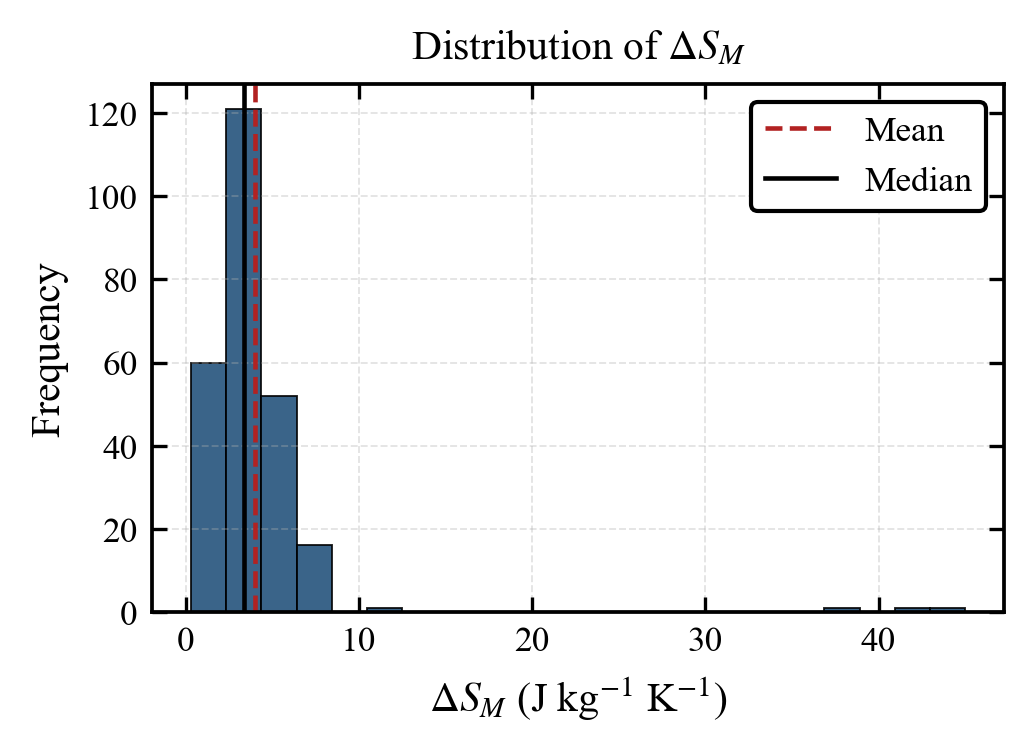

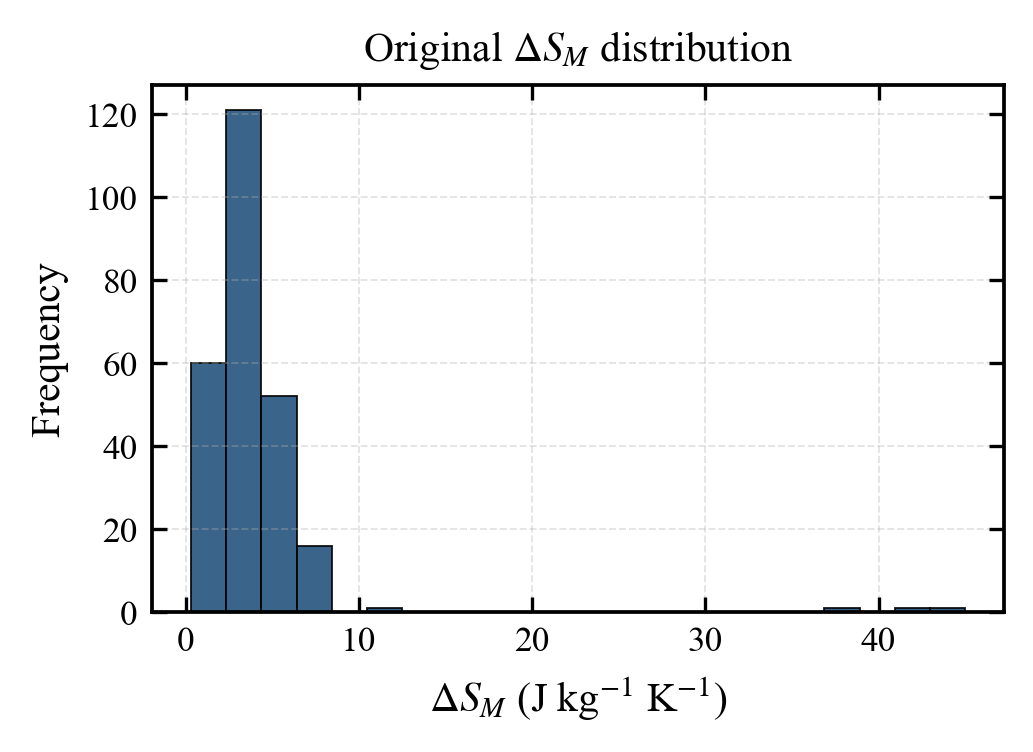

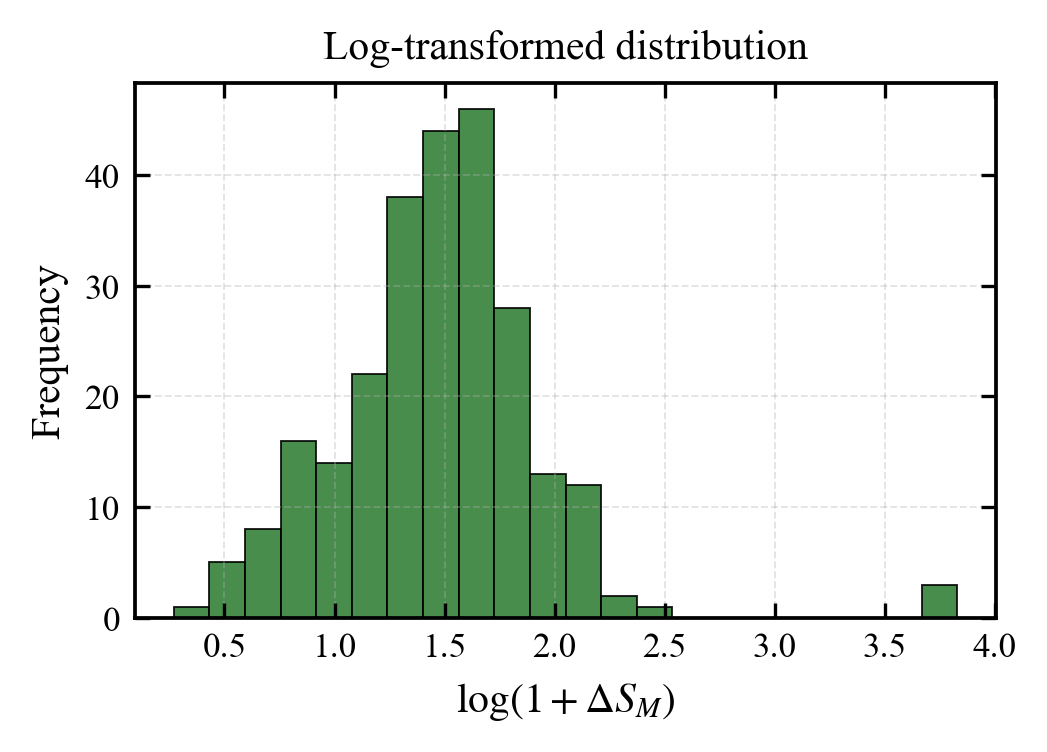

In [7]:
plot_delta_s_histogram(delta_s)
plot_transformation_histogram(y_original)

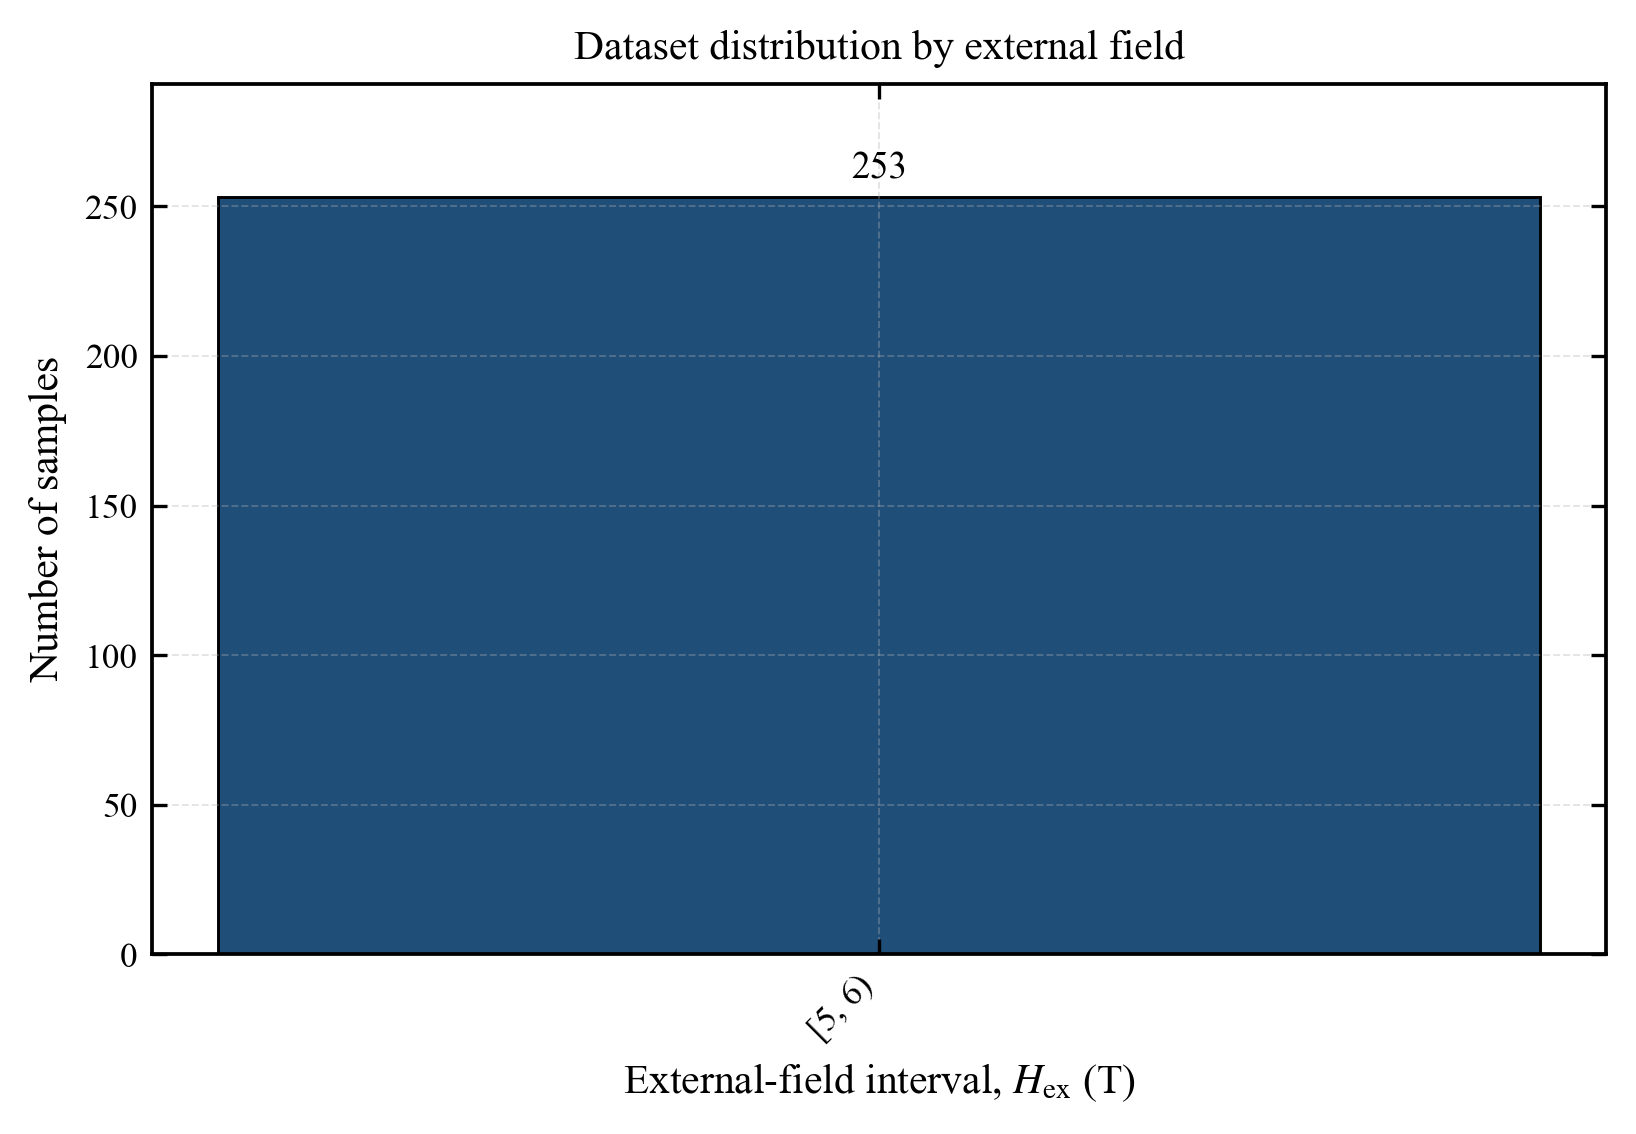

In [8]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# --- локальные fallback-настройки, если стилевая ячейка ещё не выполнена ---
CM_TO_INCH = 1 / 2.54
COLUMN_WIDTH = globals().get("COLUMN_WIDTH", 8.5 * CM_TO_INCH)
COLORS = globals().get("COLORS", {
    "blue": "#1f4e79", "red": "#b22222", "green": "#2e7d32",
    "gray": "#666666", "black": "#000000",
})
out_dir = globals().get("out_dir", "DCD_paper")
os.makedirs(out_dir, exist_ok=True)

if "format_axes" not in globals():
    def format_axes(ax, grid=True):
        ax.tick_params(direction="in", top=True, right=True)
        if grid:
            ax.grid(True, linestyle="--", linewidth=0.45, alpha=0.35)
        for spine in ax.spines.values():
            spine.set_linewidth(0.9)

if "save_figure" not in globals():
    def save_figure(fig, name):
        fig.savefig(os.path.join(out_dir, f"{name}.png"), dpi=600)


def plot_field_distribution(df, field_col="Magnetic Field", bin_width=1.0, name="Fig_field_distribution"):
    if field_col not in df.columns:
        raise KeyError(f"Column '{field_col}' not found. Available: {list(df.columns)}")

    field = pd.to_numeric(df[field_col], errors="coerce").dropna()
    if field.empty:
        raise ValueError(f"Column '{field_col}' has no valid numeric values.")

    bin_min = np.floor(field.min())
    bin_max = np.ceil(field.max())
    n_bins = max(1, int(np.ceil((bin_max - bin_min) / bin_width)))
    edges = bin_min + np.arange(n_bins + 1) * bin_width

    counts, edges = np.histogram(field, bins=edges)
    labels = [f"[{edges[i]:g}, {edges[i+1]:g})" for i in range(len(edges) - 1)]

    order = [(lab, c) for lab, c in zip(labels, counts) if c > 0]
    if not order:
        raise ValueError("All bins are empty — check field_col and bin_width.")
    order.sort(key=lambda x: x[1], reverse=True)
    labels_sorted, counts_sorted = zip(*order)

    fig, ax = plt.subplots(figsize=(COLUMN_WIDTH * 1.6, COLUMN_WIDTH * 1.1))

    bars = ax.bar(
        labels_sorted, counts_sorted,
        color=COLORS["blue"],
        edgecolor=COLORS["black"],
        linewidth=0.7,
        width=0.7,
    )

    for bar, val in zip(bars, counts_sorted):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            val + max(counts_sorted) * 0.015,
            f"{val}",
            ha="center", va="bottom", fontsize=9
        )

    ax.set_xlabel(r"External-field interval, $H_{\mathrm{ex}}$ (T)")
    ax.set_ylabel("Number of samples")
    ax.set_title("Dataset distribution by external field")
    ax.set_ylim(0, max(counts_sorted) * 1.15)

    plt.setp(ax.get_xticklabels(), rotation=45, ha="right")

    format_axes(ax, grid=True)
    fig.tight_layout(pad=0.4)
    save_figure(fig, name)
    plt.show()


plot_field_distribution(df, field_col="Magnetic Field")

# Отбор признаков через RFECV и обучение моделей

In [9]:
optuna.logging.set_verbosity(optuna.logging.WARNING)

model_matrix_dir = os.path.join(out_dir, "model_matrix")
os.makedirs(model_matrix_dir, exist_ok=True)

field_split_dir = os.path.join(out_dir, "field_split")
os.makedirs(field_split_dir, exist_ok=True)


rfecv_base_estimators = {
    "Ridge": Ridge(alpha=1.0),
    "Lasso": Lasso(alpha=0.01, max_iter=10000),
    "ElasticNet": ElasticNet(alpha=0.01, l1_ratio=0.5, max_iter=10000),
    "Random Forest": RandomForestRegressor(n_estimators=200, max_depth=10, min_samples_leaf=3, random_state=42, n_jobs=-1),
    "XGBoost": xgb.XGBRegressor(
        n_estimators=100, max_depth=4, learning_rate=0.05,
        reg_alpha=0.1, reg_lambda=1.0, subsample=0.8, colsample_bytree=0.8,
        random_state=42, verbosity=0, objective="reg:squarederror"
    ),
    "CatBoost": CatBoostRegressor(
        iterations=300, depth=4, learning_rate=0.05,
        l2_leaf_reg=3.0, subsample=0.8, bootstrap_type="Bernoulli",
        random_state=42, verbose=False
    ),
    "Neural Net": MLPRegressorRFE(
        hidden_layer_sizes=(32, 16), alpha=1e-3, max_iter=800,
        early_stopping=True, n_iter_no_change=15, random_state=42
    ),
}

N_TRIALS = {
    "Ridge": 40, "Lasso": 40, "ElasticNet": 60,
    "Random Forest": 300, "XGBoost": 300,
    "CatBoost": 300, "Neural Net": 150,
}

# для NN на ~250 фичах RFE с шагом 1 будет слишком долго — убираем пачками
RFE_STEP = {
    "Ridge": 1, "Lasso": 1, "ElasticNet": 1,
    "Random Forest": 1, "XGBoost": 1, "CatBoost": 1,
    "Neural Net": 10,
}

drop_cols = [
    "Original_index", "Compound", "Clean_formula", "Property",
    "Reference", "Magnetic Field", "log_delta_S_M", "Is_target_outlier",
    target,
]

FIELD_BINS = [(5, 6)]  # один интервал, дальше по коду ничего менять не надо

model_features = {}
dirty_models = {}
dirty_residuals_info = {}
optuna_studies_dirty = {}

for field_min, field_max in FIELD_BINS:
    field_mask = (df["Magnetic Field"] >= field_min) & (df["Magnetic Field"] < field_max)
    df_field = df.loc[field_mask].copy()
    n_points = len(df_field)

    print(f"\n\n########## Диапазон {field_min}-{field_max} Т: {n_points} точек ##########")

    if n_points < 15:
        print(f"Пропуск: слишком мало точек ({n_points})")
        continue

    X_field = df_field.drop(columns=drop_cols, errors="ignore")
    X_field = X_field.select_dtypes(include=[np.number])
    X_field = X_field.fillna(X_field.median())

    if X_field.shape[1] > 1:
        corr_matrix = X_field.corr().abs()
        upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
        to_drop = [c for c in upper.columns if any(upper[c] > 0.95)]
        X_field = X_field.drop(columns=to_drop)

    if "Magnetic Field" in X_field.columns:
        X_field = X_field.drop(columns=["Magnetic Field"])

    y_original_field = df_field[target].values
    skew_field = pd.Series(y_original_field).skew()
    target_transformed_field = abs(skew_field) > 1
    y_field = np.log1p(y_original_field) if target_transformed_field else y_original_field.copy()

    scaler_field = StandardScaler()
    X_scaled_field = scaler_field.fit_transform(X_field)

    n_splits_field = max(2, min(5, n_points // 5))
    cv_field = KFold(n_splits=n_splits_field, shuffle=True, random_state=42)

    for model_name, base_estimator in rfecv_base_estimators.items():
        key = f"{model_name}__{field_min}-{field_max}T"
        print(f"\n--- {key}: RFE10 ---")

        try:
            n_select = min(10, X_field.shape[1])
            rfe_model = RFE(
                estimator=clone(base_estimator),
                n_features_to_select=n_select,
                step=RFE_STEP.get(model_name, 1),
            )
            rfe_model.fit(X_scaled_field, y_field)

            feature_list = list(X_field.columns[rfe_model.support_])
            model_features[key] = feature_list
            print(f"{key}: признаков = {len(feature_list)}")

            mask = X_field.columns.isin(feature_list)
            X_model = X_scaled_field[:, mask]

            dirty_model, dirty_params, dirty_score, dirty_study = run_optuna_search(
                model_name, X_model, y_field, cv_field, N_TRIALS[model_name]
            )
            dirty_model.fit(X_model, y_field)
            optuna_studies_dirty[key] = dirty_study

            y_pred_cv = cross_val_predict(clone(dirty_model), X_model, y_field, cv=cv_field)
            if target_transformed_field:
                y_orig_m = np.expm1(y_field)
                y_pred_cv_orig = np.expm1(y_pred_cv)
            else:
                y_orig_m = y_field.copy()
                y_pred_cv_orig = y_pred_cv.copy()

            r2_physical = r2_score(y_orig_m, y_pred_cv_orig)
            mae_physical = mean_absolute_error(y_orig_m, y_pred_cv_orig)

            print(f"{key}: best params = {dirty_params}")
            print(f"{key}: R2 (transformed) = {dirty_score:.4f}, R2 (physical) = {r2_physical:.4f}")

            dirty_models[key] = dirty_model
            dirty_residuals_info[key] = {
                "y_orig_m": y_orig_m,
                "y_pred_cv_orig": y_pred_cv_orig,
                "y_true_log": y_field.copy(),
                "y_pred_log": y_pred_cv.copy(),
                "r2_transformed": dirty_score,
                "mae_transformed": mean_absolute_error(y_field, y_pred_cv),
            }

        except Exception as e:
            print(f"{key}: ОШИБКА — {e}")
            continue

# --- сводная таблица прямо здесь ---
summary_rows = []
for key, info in dirty_residuals_info.items():
    model_name, field_range = key.split("__")
    summary_rows.append({
        "Model": model_name,
        "Field range": field_range,
        "N_features (RFE10)": len(model_features[key]),
        "R2_physical": r2_score(info["y_orig_m"], info["y_pred_cv_orig"]),
        "MAE_physical": mean_absolute_error(info["y_orig_m"], info["y_pred_cv_orig"]),
    })

summary_df = pd.DataFrame(summary_rows).sort_values("R2_physical", ascending=False).reset_index(drop=True)
print("\n\n=== Сводная таблица (RFE10, диапазон {}) ===".format(FIELD_BINS[0]))
print(summary_df.to_string(index=False))
summary_df.to_excel(os.path.join(field_split_dir, "rfe10_summary.xlsx"), index=False)



########## Диапазон 5-6 Т: 253 точек ##########

--- Ridge__5-6T: RFE10 ---
Ridge__5-6T: признаков = 10


Best trial: 21. Best value: 0.42074: 100%|██████████| 40/40 [00:06<00:00,  6.27it/s] 


Ridge__5-6T: best params = {'alpha': 1.3639966842620097}
Ridge__5-6T: R2 (transformed) = 0.4207, R2 (physical) = 0.7913

--- Lasso__5-6T: RFE10 ---
Lasso__5-6T: признаков = 10


Best trial: 11. Best value: 0.498144: 100%|██████████| 40/40 [00:00<00:00, 73.47it/s]


Lasso__5-6T: best params = {'alpha': 1.0266895107989368e-06}
Lasso__5-6T: R2 (transformed) = 0.4981, R2 (physical) = 0.8277

--- ElasticNet__5-6T: RFE10 ---
ElasticNet__5-6T: признаков = 10


Best trial: 59. Best value: 0.501749: 100%|██████████| 60/60 [00:00<00:00, 65.26it/s]


... (5 outputs left out)

Best trial: 164. Best value: 0.650713: 100%|██████████| 300/300 [01:35<00:00,  3.13it/s]


CatBoost__5-6T: best params = {'iterations': 452, 'depth': 4, 'learning_rate': 0.03238354227185981, 'l2_leaf_reg': 2.699062809503896, 'subsample': 0.668302525794057}
CatBoost__5-6T: R2 (transformed) = 0.6507, R2 (physical) = 0.9022

--- Neural Net__5-6T: RFE10 ---
Neural Net__5-6T: признаков = 10


Best trial: 35. Best value: 0.433683: 100%|██████████| 150/150 [00:54<00:00,  2.74it/s]


Neural Net__5-6T: best params = {'n_layers': 1, 'n_units_l0': 32, 'alpha': 0.10835699686294234, 'learning_rate_init': 0.001646976119795888, 'activation': 'relu'}
Neural Net__5-6T: R2 (transformed) = 0.4337, R2 (physical) = 0.8156


=== Сводная таблица (RFE10, диапазон (5, 6)) ===
        Model Field range  N_features (RFE10)  R2_physical  MAE_physical
     CatBoost        5-6T                  10     0.902194      0.948706
      XGBoost        5-6T                  10     0.868443      1.027296
        Lasso        5-6T                  10     0.827669      1.202881
   ElasticNet        5-6T                  10     0.821165      1.212057
   Neural Net        5-6T                  10     0.815636      1.267341
        Ridge        5-6T                  10     0.791251      1.276781
Random Forest        5-6T                  10     0.615773      1.203737


In [10]:
field_ranges_seen = []
for key in model_features.keys():
    model_name, field_range = key.split("__")
    if field_range not in field_ranges_seen:
        field_ranges_seen.append(field_range)

field_summary_tables = {}

for field_range in field_ranges_seen:
    rows = []
    for key in model_features.keys():
        model_name, key_field_range = key.split("__")
        if key_field_range != field_range:
            continue

        info = dirty_residuals_info[key]
        rows.append({
            "Model": model_name,
            "N_features": len(model_features[key]),
            "R2_transformed": info["r2_transformed"],
            "MAE_transformed": info["mae_transformed"],
            "R2_physical": r2_score(info["y_orig_m"], info["y_pred_cv_orig"]),
            "MAE_physical": mean_absolute_error(info["y_orig_m"], info["y_pred_cv_orig"]),
        })

    table = pd.DataFrame(rows).sort_values("R2_physical", ascending=False).reset_index(drop=True)
    field_summary_tables[field_range] = table

    print(f"\n=== ТАБЛИЦА, диапазон {field_range} Т ===")
    print(table.to_string(index=False))

    table.to_excel(
        os.path.join(field_split_dir, f"model_metrics_field_{field_range.replace('-', '_')}.xlsx"),
        index=False
    )


=== ТАБЛИЦА, диапазон 5-6T Т ===
        Model  N_features  R2_transformed  MAE_transformed  R2_physical  MAE_physical
     CatBoost          10        0.650713         0.203521     0.902194      0.948706
      XGBoost          10        0.633618         0.213344     0.868443      1.027296
        Lasso          10        0.498144         0.249616     0.827669      1.202881
   ElasticNet          10        0.501749         0.248593     0.821165      1.212057
   Neural Net          10        0.433683         0.266630     0.815636      1.267341
        Ridge          10        0.420740         0.262964     0.791251      1.276781
Random Forest          10        0.584060         0.222522     0.615773      1.203737


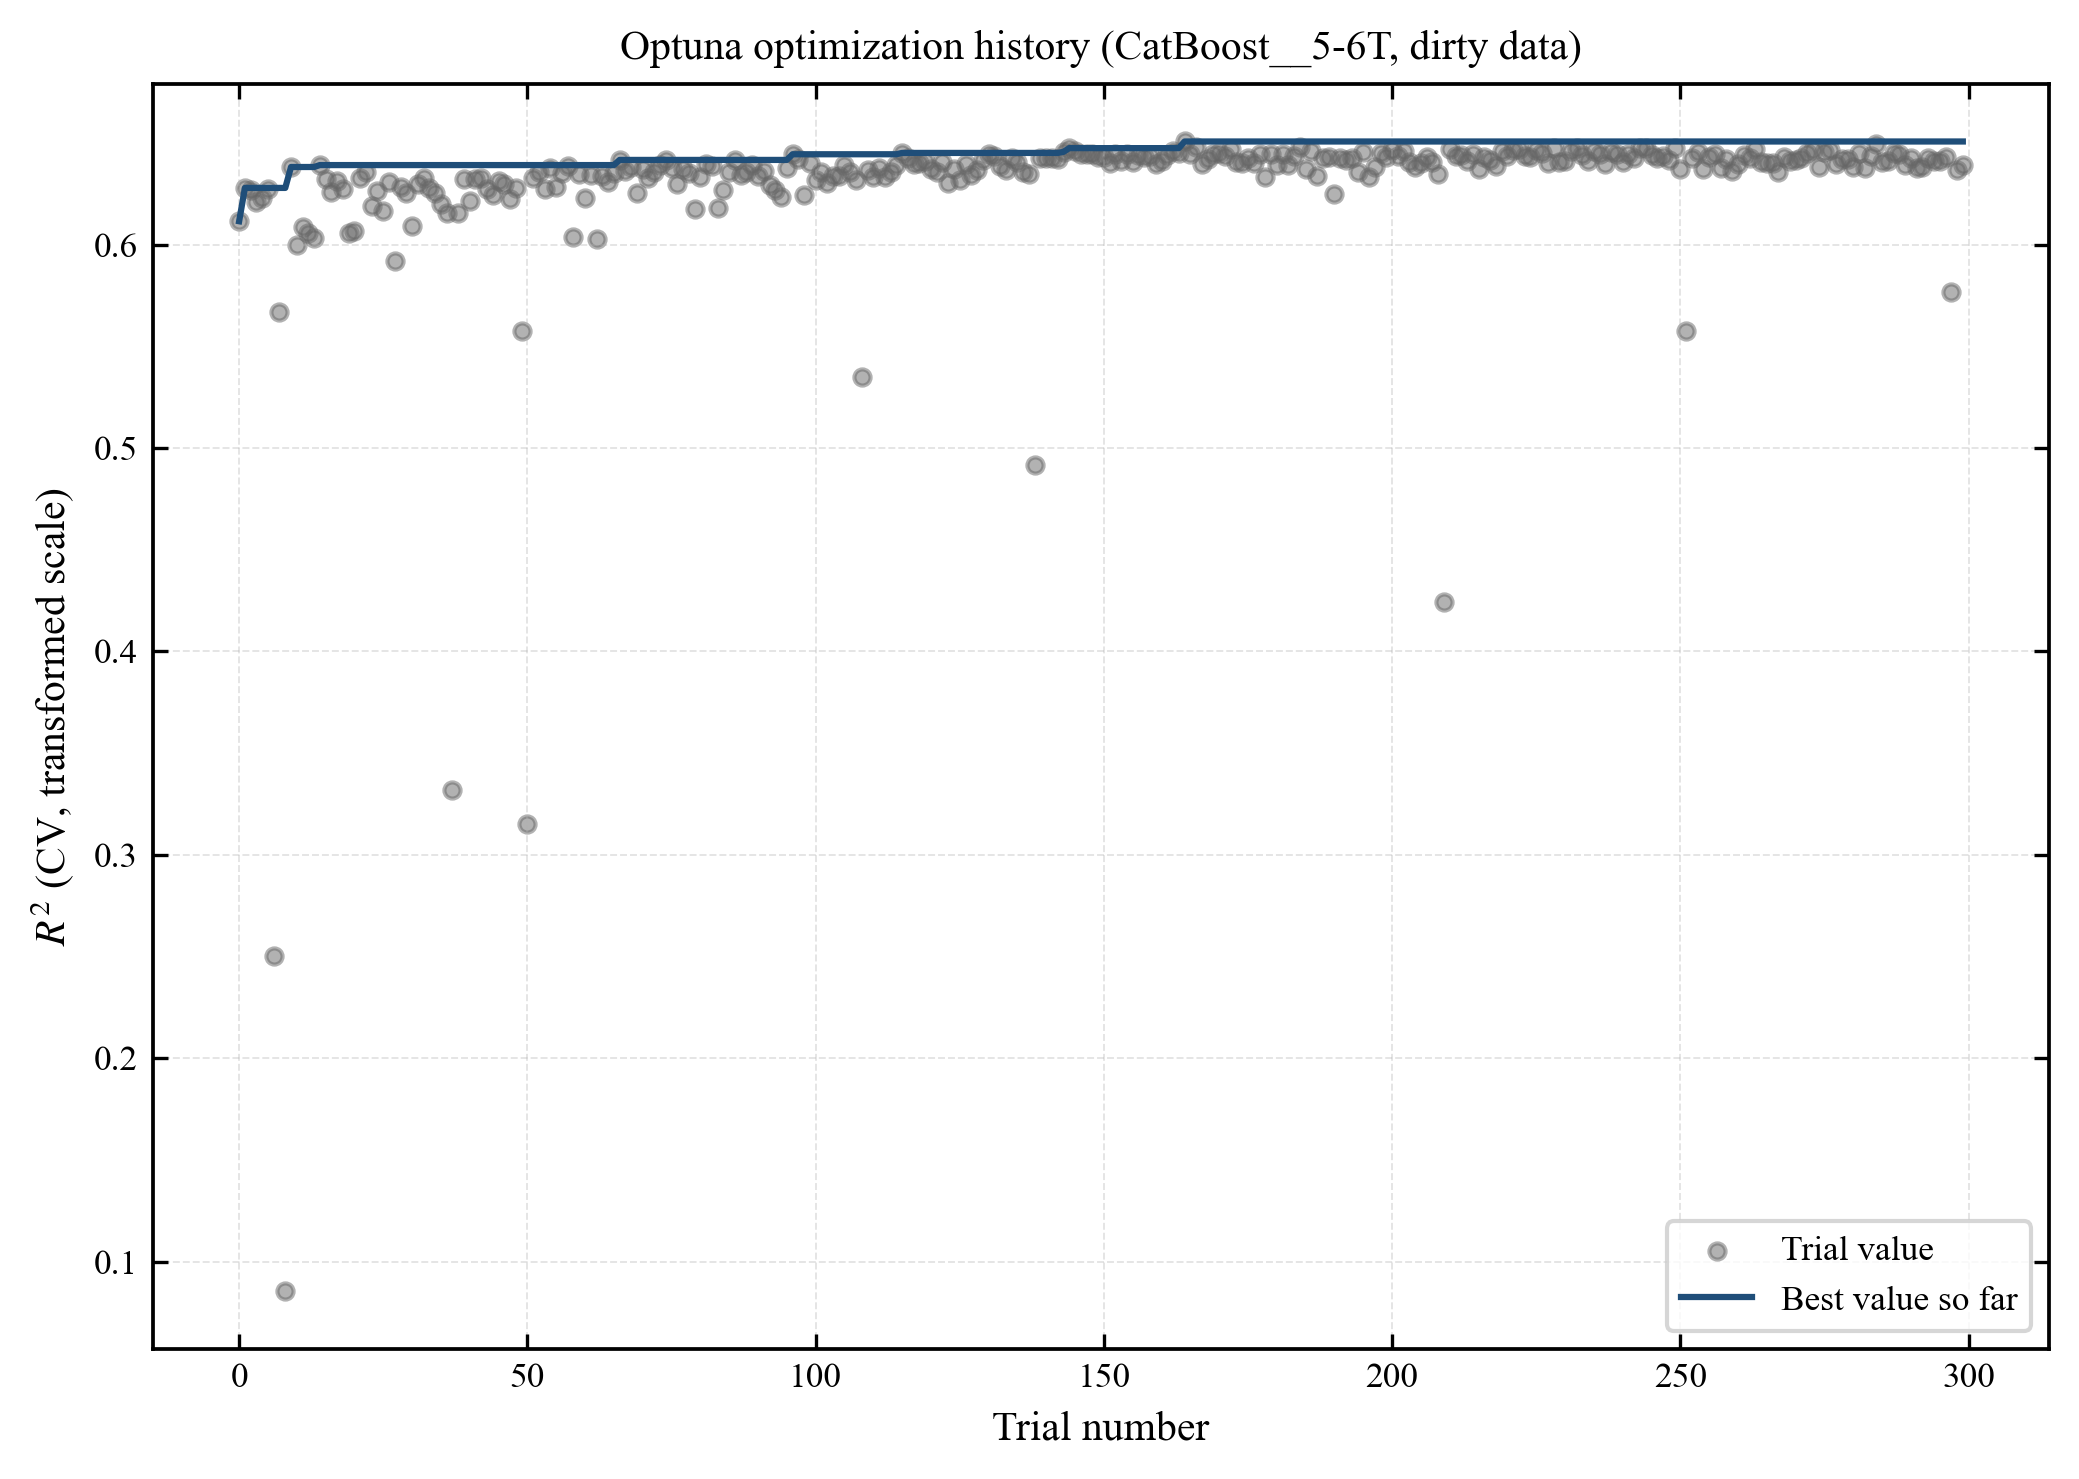

In [11]:
key = "CatBoost__5-6T"  # или соберите динамически, см. ниже

trials_df = optuna_studies_dirty[key].trials_dataframe()
best_so_far = trials_df["value"].cummax()

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(trials_df["number"], trials_df["value"], s=15, color=COLORS["gray"], alpha=0.5, label="Trial value")
ax.plot(trials_df["number"], best_so_far, color=COLORS["blue"], linewidth=1.5, label="Best value so far")
ax.set_xlabel("Trial number")
ax.set_ylabel(r"$R^2$ (CV, transformed scale)")
ax.set_title(f"Optuna optimization history ({key}, dirty data)")
ax.legend(loc="lower right")
format_axes(ax)
fig.tight_layout()
plt.show()

# Оценка метрик качества и удаление выбросов

In [12]:
clean_data_per_field_model = {}

for key, info in dirty_residuals_info.items():
    print(f"\n========== {key}: поиск и удаление выбросов ==========")

    model_name, field_range = key.split("__")
    field_min_str, field_max_str = field_range.replace("T", "").split("-")
    field_min, field_max = float(field_min_str), float(field_max_str)

    is_last_bin = (field_min, field_max) == FIELD_BINS[-1]
    if is_last_bin:
        field_mask = (df["Magnetic Field"] >= field_min) & (df["Magnetic Field"] <= field_max)
    else:
        field_mask = (df["Magnetic Field"] >= field_min) & (df["Magnetic Field"] < field_max)
    df_field = df.loc[field_mask].copy()

    # --- остатки на ФИЗИЧЕСКОЙ шкале (J/kg*K), не log ---
    residuals = info["y_pred_cv_orig"] - info["y_orig_m"]

    threshold = 2.5 * residuals.std()
    is_outlier = np.abs(residuals) > threshold
    outlier_labels = df_field.index.values[is_outlier]

    print(f"Residual std (physical scale) = {residuals.std():.4f}, threshold = {threshold:.4f}")
    print(f"Выбросов найдено: {is_outlier.sum()} из {len(df_field)}")

    if is_outlier.sum() > 0:
        outlier_formulas = (df_field["Clean_formula"].values[is_outlier]
                             if "Clean_formula" in df_field.columns else outlier_labels)
        print(pd.DataFrame({
            "formula": outlier_formulas,
            "y_true": info["y_orig_m"][is_outlier],
            "residual_physical": residuals[is_outlier]
        }).to_string(index=False))

    # --- новый очищенный датасет для этого (модель, диапазон) ---
    df_field_clean = df_field.drop(index=outlier_labels).copy()

    X_field_clean = df_field_clean.drop(columns=drop_cols, errors="ignore")
    X_field_clean = X_field_clean.select_dtypes(include=[np.number])
    X_field_clean = X_field_clean.fillna(X_field_clean.median())

    if X_field_clean.shape[1] > 1:
        corr_matrix = X_field_clean.corr().abs()
        upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
        to_drop = [c for c in upper.columns if any(upper[c] > 0.95)]
        X_field_clean = X_field_clean.drop(columns=to_drop)

    if "Magnetic Field" in X_field_clean.columns:
        X_field_clean = X_field_clean.drop(columns=["Magnetic Field"])

    y_original_field_clean = df_field_clean[target].values
    skew_field_clean = pd.Series(y_original_field_clean).skew()
    target_transformed_field_clean = abs(skew_field_clean) > 1
    y_field_clean = (np.log1p(y_original_field_clean) if target_transformed_field_clean
                      else y_original_field_clean.copy())

    scaler_field_clean = StandardScaler()
    X_scaled_field_clean = scaler_field_clean.fit_transform(X_field_clean)

    n_splits_clean = max(2, min(5, len(df_field_clean) // 5))
    cv_field_clean = KFold(n_splits=n_splits_clean, shuffle=True, random_state=42)

    feature_list = model_features[key]
    feature_list_present = [f for f in feature_list if f in X_field_clean.columns]
    missing = set(feature_list) - set(feature_list_present)
    if missing:
        print(f"ВНИМАНИЕ: признаки пропали после чистки: {missing}")

    mask_clean = X_field_clean.columns.isin(feature_list_present)
    X_final = X_scaled_field_clean[:, mask_clean]

    print(f"Dataset size after cleaning: {len(df_field_clean)} rows (was {len(df_field)}), "
          f"features used: {mask_clean.sum()}")

    clean_data_per_field_model[key] = {
        "df_model_clean": df_field_clean,
        "X_final": X_final,
        "y_model_clean": y_field_clean,
        "cv_clean": cv_field_clean,
        "feature_list_present": feature_list_present,
        "target_transformed_model_clean": target_transformed_field_clean,
        "n_outliers": int(is_outlier.sum()),
        "n_features_used": int(mask_clean.sum()),
    }


========== Ridge__5-6T: поиск и удаление выбросов ==========
Residual std (physical scale) = 2.0115, threshold = 5.0287
Выбросов найдено: 4 из 253
              formula  y_true  residual_physical
   EuTi0.875Zn0.125O3   41.10         -12.556014
 EuTi0.8125Zn0.1875O3   45.00         -16.655408
               HoCrO3    3.22           6.003464
La0.7Ca0.25Sr0.05MnO3   10.50          -6.768741
Dataset size after cleaning: 249 rows (was 253), features used: 10

========== Lasso__5-6T: поиск и удаление выбросов ==========
Residual std (physical scale) = 1.8283, threshold = 4.5707
Выбросов найдено: 5 из 253
                    formula  y_true  residual_physical
       EuTi0.9375Zn0.0625O3    38.5          -8.601557
         EuTi0.875Zn0.125O3    41.1         -10.072510
       EuTi0.8125Zn0.1875O3    45.0         -13.968858
La1.3Eu0.1Sr0.05Ca1.55Mn2O7     7.1          -5.838578
      La0.7Ca0.25Sr0.05MnO3    10.5          -5.751347
Dataset size after cleaning: 248 rows (was 253), features used

In [13]:
saved_models_field = {}
saved_data_field = {}
optuna_results_field = []
optuna_studies_field_clean = {}

for key, clean_info in clean_data_per_field_model.items():
    model_name, field_range = key.split("__")
    print(f"\n========== {key} (Optuna на чистых данных, {N_TRIALS[model_name]} trials) ==========")

    X_final = clean_info["X_final"]
    y_model_clean = clean_info["y_model_clean"]
    cv_clean = clean_info["cv_clean"]

    clean_model, clean_params, clean_score, clean_study = run_optuna_search(
        model_name, X_final, y_model_clean, cv_clean, N_TRIALS[model_name]
    )
    clean_model.fit(X_final, y_model_clean)
    optuna_studies_field_clean[key] = clean_study

    y_pred_final = cross_val_predict(clone(clean_model), X_final, y_model_clean, cv=cv_clean)
    mae_transformed_clean = mean_absolute_error(y_model_clean, y_pred_final)

    if clean_info["target_transformed_model_clean"]:
        y_orig_final = np.expm1(y_model_clean)
        y_pred_final_orig = np.expm1(y_pred_final)
    else:
        y_orig_final = y_model_clean.copy()
        y_pred_final_orig = y_pred_final.copy()

    r2_physical = r2_score(y_orig_final, y_pred_final_orig)
    mae_physical = mean_absolute_error(y_orig_final, y_pred_final_orig)

    print(f"{key}: best params (clean) = {clean_params}")
    print(f"{key}: R2 (transformed CV) = {clean_score:.4f}, "
          f"R2 (physical) = {r2_physical:.4f}, MAE (physical) = {mae_physical:.4f}")

    saved_models_field[key] = clean_model
    saved_data_field[key] = {
        "X_final": X_final,
        "y_model_clean": y_model_clean,
        "cv_clean_seed": cv_clean,
        "feature_list_present": clean_info["feature_list_present"],
        "target_transformed": clean_info["target_transformed_model_clean"],
        "y_orig_final": y_orig_final,
        "y_pred_final_orig": y_pred_final_orig,
        "r2_physical": r2_physical,
        "mae_physical": mae_physical,
        "r2_transformed": clean_score,
        "mae_transformed": mae_transformed_clean,
        "df_model_clean": clean_info["df_model_clean"],
    }

    optuna_results_field.append({
        "Model": model_name,
        "Field_range": field_range,
        "N_features": clean_info["n_features_used"],
        "N_outliers_removed": clean_info["n_outliers"],
        "Best_hyperparameters": str(clean_params),
        "R2_CV_transformed": clean_score,
        "MAE_CV_transformed": mae_transformed_clean,
        "R2_CV_physical": r2_physical,
        "MAE_CV_physical": mae_physical,
    })

optuna_results_field_df = pd.DataFrame(optuna_results_field).sort_values(
    ["Field_range", "R2_CV_physical"], ascending=[True, False]
)
optuna_results_field_df.to_excel(os.path.join(field_split_dir, "optuna_results_field.xlsx"), index=False)

# --- отдельная таблица на каждый диапазон ---
field_ranges_seen = optuna_results_field_df["Field_range"].unique()

for field_range in field_ranges_seen:
    table = optuna_results_field_df[optuna_results_field_df["Field_range"] == field_range].drop(
        columns=["Field_range"]
    ).reset_index(drop=True)

    print(f"\n=== ТАБЛИЦА, диапазон {field_range} Т (очищенные данные) ===")
    print(table.to_string(index=False))

    table.to_excel(
        os.path.join(field_split_dir, f"model_metrics_field_{field_range.replace('-', '_')}_clean.xlsx"),
        index=False
    )


========== Ridge__5-6T (Optuna на чистых данных, 40 trials) ==========


Best trial: 11. Best value: 0.290661: 100%|██████████| 40/40 [00:00<00:00, 74.40it/s]


Ridge__5-6T: best params (clean) = {'alpha': 0.0010266895107989367}
Ridge__5-6T: R2 (transformed CV) = 0.2907, R2 (physical) = 0.5996, MAE (physical) = 1.1750

========== Lasso__5-6T (Optuna на чистых данных, 40 trials) ==========


Best trial: 11. Best value: 0.372382: 100%|██████████| 40/40 [00:00<00:00, 71.60it/s]


Lasso__5-6T: best params (clean) = {'alpha': 1.0266895107989368e-06}
Lasso__5-6T: R2 (transformed CV) = 0.3724, R2 (physical) = 0.3857, MAE (physical) = 1.0091

========== ElasticNet__5-6T (Optuna на чистых данных, 60 trials) ==========


Best trial: 58. Best value: 0.364022: 100%|██████████| 60/60 [00:00<00:00, 70.71it/s]


... (5 outputs left out)

Best trial: 251. Best value: 0.63863: 100%|██████████| 300/300 [01:57<00:00,  2.55it/s] 


CatBoost__5-6T: best params (clean) = {'iterations': 419, 'depth': 4, 'learning_rate': 0.1351263354820872, 'l2_leaf_reg': 14.582919497241324, 'subsample': 0.6259551663654654}
CatBoost__5-6T: R2 (transformed CV) = 0.6386, R2 (physical) = 0.8770, MAE (physical) = 0.8497

========== Neural Net__5-6T (Optuna на чистых данных, 150 trials) ==========


Best trial: 79. Best value: 0.31519: 100%|██████████| 150/150 [00:26<00:00,  5.73it/s]


Neural Net__5-6T: best params (clean) = {'n_layers': 1, 'n_units_l0': 14, 'alpha': 0.5732147563775923, 'learning_rate_init': 0.006934139672584116, 'activation': 'relu'}
Neural Net__5-6T: R2 (transformed CV) = 0.3152, R2 (physical) = 0.5195, MAE (physical) = 1.1957

=== ТАБЛИЦА, диапазон 5-6T Т (очищенные данные) ===
        Model  N_features  N_outliers_removed                                                                                                                                                                                                                                   Best_hyperparameters  R2_CV_transformed  MAE_CV_transformed  R2_CV_physical  MAE_CV_physical
     CatBoost          10                   7                                                                                                               {'iterations': 419, 'depth': 4, 'learning_rate': 0.1351263354820872, 'l2_leaf_reg': 14.582919497241324, 'subsample': 0.6259551663654654}           0.638630      

In [14]:
overfit_rows = []

for key, model in saved_models_field.items():
    model_name, field_range = key.split("__")
    clean_info = clean_data_per_field_model[key]
    data = saved_data_field[key]

    train_r2_log = model.score(clean_info["X_final"], clean_info["y_model_clean"])
    cv_r2_log = data["r2_transformed"]
    gap = train_r2_log - cv_r2_log

    overfit_rows.append({
        "Model": model_name,
        "Field range": field_range,
        "Train R2 (log)": train_r2_log,
        "CV R2 (log)": cv_r2_log,
        "Gap (train - CV)": gap,
        "R2 physical": data["r2_physical"],
        "MAE physical": data["mae_physical"],
    })

overfit_df = pd.DataFrame(overfit_rows).sort_values("Gap (train - CV)", ascending=False).reset_index(drop=True)

print("=== Train vs CV — поиск переобучения ===")
print(overfit_df.to_string(index=False))

overfit_df.to_excel(os.path.join(field_split_dir, "train_cv_overfit_check.xlsx"), index=False)

=== Train vs CV — поиск переобучения ===
        Model Field range  Train R2 (log)  CV R2 (log)  Gap (train - CV)  R2 physical  MAE physical
      XGBoost        5-6T        0.842758     0.439656          0.403102     0.123882      1.015822
Random Forest        5-6T        0.745393     0.383783          0.361610     0.401679      0.978252
     CatBoost        5-6T        0.914346     0.638630          0.275716     0.877003      0.849745
        Ridge        5-6T        0.426516     0.290661          0.135855     0.599618      1.175003
        Lasso        5-6T        0.434258     0.372382          0.061876     0.385695      1.009150
   ElasticNet        5-6T        0.419499     0.364022          0.055477     0.381021      1.001738
   Neural Net        5-6T        0.199886     0.315190         -0.115305     0.519476      1.195689


# Применение модели CatBoost на 1 Тл

Found 74 compositions measured at both 1T and 5T
                  Clean_formula  delta_S_M_1T  delta_S_M_5T  n_empirical
         La0.62Bi0.05Ba0.33MnO3      1.420000          7.30     1.017260
     La0.67Ba0.33Mn0.98Ti0.02O3      0.930000          3.24     0.775515
          La0.67Sr0.1Ca0.23MnO3      2.430000          5.97     0.558490
La0.65Eu0.05Sr0.3Mn0.95Cr0.05O3      1.280000          4.04     0.714153
  La0.65Eu0.05Sr0.3Mn0.9Cr0.1O3      0.980000          3.35     0.763722
La0.65Eu0.05Sr0.3Mn0.85Cr0.15O3      0.780000          2.65     0.759906
       La0.67Ba0.33Mn0.9Cr0.1O3      1.560000          4.20     0.615369
           EuTi0.9375Zn0.0625O3     10.300000         38.50     0.819239
             EuTi0.875Zn0.125O3     10.800000         41.10     0.830391
           EuTi0.8125Zn0.1875O3     12.500000         45.00     0.795889
          La0.47Pr0.2Pb0.33MnO3      1.290000          3.96     0.696890
                 La0.7Ba0.3MnO3      1.040000          4.50     0.910167
  

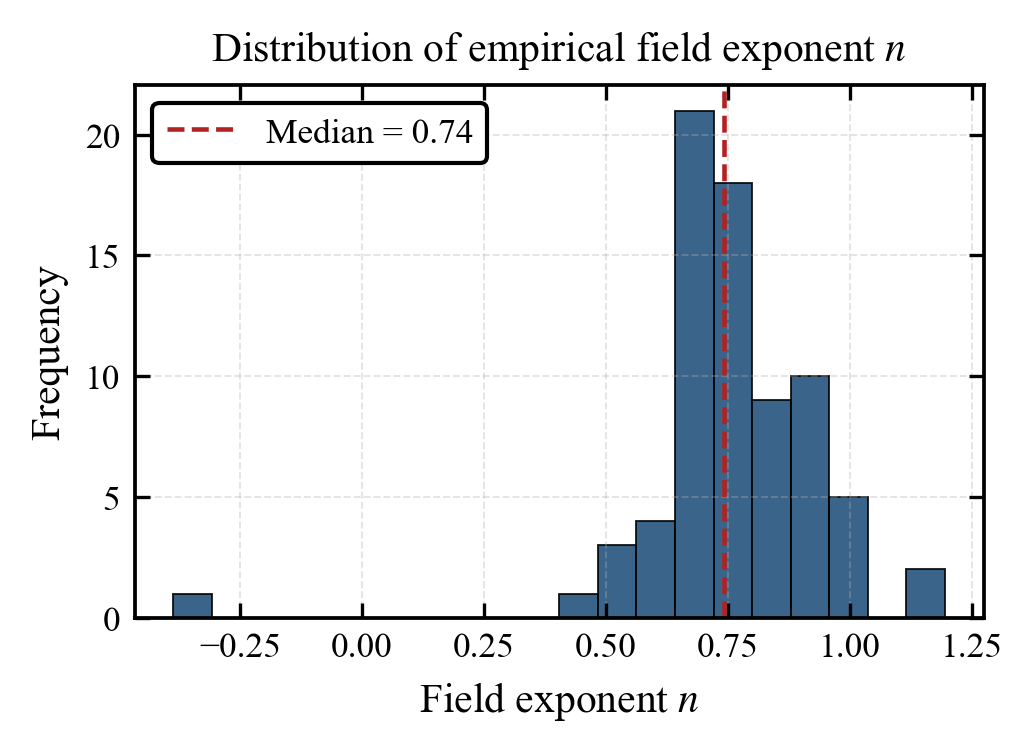

In [15]:
df5 = pd.read_excel("ME_5T_XenonPy_descriptors.xlsx")
df1 = pd.read_excel("ME_1T_XenonPy_descriptors.xlsx")

df5_small = df5[["Clean_formula", "delta_S_M"]].rename(columns={"delta_S_M": "delta_S_M_5T"})
df1_small = df1[["Clean_formula", "delta_S_M"]].rename(columns={"delta_S_M": "delta_S_M_1T"})

paired = df5_small.merge(df1_small, on="Clean_formula", how="inner")
print(f"Found {len(paired)} compositions measured at both 1T and 5T")

# отбрасываем неположительные/некорректные значения — log не определён
paired = paired[(paired["delta_S_M_5T"] > 0) & (paired["delta_S_M_1T"] > 0)].copy()

paired["n_empirical"] = np.log(paired["delta_S_M_5T"] / paired["delta_S_M_1T"]) / np.log(5.0)

print(paired[["Clean_formula", "delta_S_M_1T", "delta_S_M_5T", "n_empirical"]].to_string(index=False))
print(f"\nMedian n = {paired['n_empirical'].median():.3f}")
print(f"Mean n = {paired['n_empirical'].mean():.3f}")
print(f"Std n = {paired['n_empirical'].std():.3f}")

fig, ax = plt.subplots(figsize=(COLUMN_WIDTH, COLUMN_WIDTH * 0.72))

ax.hist(
    paired["n_empirical"],
    bins=20,
    color=COLORS["blue"],
    edgecolor=COLORS["black"],
    linewidth=0.45,
    alpha=0.88
)

ax.axvline(
    paired["n_empirical"].median(),
    color=COLORS["red"],
    linestyle="--",
    linewidth=1.1,
    label=f"Median = {paired['n_empirical'].median():.2f}"
)

ax.set_xlabel(r"Field exponent $n$")
ax.set_ylabel("Frequency")
ax.set_title(r"Distribution of empirical field exponent $n$")

ax.legend(frameon=True, edgecolor="black", framealpha=1.0)
format_axes(ax)

fig.tight_layout(pad=0.4)
save_figure(fig, "Fig10_field_exponent_n_distribution")
plt.show()

In [16]:
df_raw = pd.read_excel("DB_mc.xlsx")
df_raw.columns = df_raw.columns.str.strip()

me_data = df_raw[df_raw["Property"].astype(str).str.strip().eq("ME (J/kg.K)")].copy()
me_data["Value"] = pd.to_numeric(me_data["Value"], errors="coerce")
me_data["Magnetic Field"] = pd.to_numeric(me_data["Magnetic Field"], errors="coerce")

# только положительные значения и валидное поле — иначе log не определён
me_data = me_data.dropna(subset=["Value", "Magnetic Field", "Compound"])
me_data = me_data[(me_data["Value"] > 0) & (me_data["Magnetic Field"] > 0)]

n_per_compound = {}
fit_quality = []

for compound, group in me_data.groupby("Compound"):
    unique_fields = group["Magnetic Field"].nunique()
    if unique_fields < 3:
        continue

    log_H = np.log(group["Magnetic Field"].values)
    log_ME = np.log(group["Value"].values)

    result = linregress(log_H, log_ME)
    n_value = result.slope
    r2_fit = result.rvalue ** 2

    n_per_compound[compound] = n_value
    fit_quality.append({
        "Compound": compound,
        "n_points": len(group),
        "unique_fields": unique_fields,
        "n": n_value,
        "R2_fit": r2_fit,
        "std_err": result.stderr,
    })

fit_df = pd.DataFrame(fit_quality).sort_values("R2_fit", ascending=False)

print(f"Составов с 3+ точками по полю: {len(n_per_compound)} из {me_data['Compound'].nunique()} уникальных составов с ME")
print(f"\nМедиана n = {fit_df['n'].median():.3f}")
print(f"Среднее n = {fit_df['n'].mean():.3f}")
print(f"Std n = {fit_df['n'].std():.3f}")
print(f"\nСредний R2 качества фита = {fit_df['R2_fit'].mean():.3f}")
print(f"\n{fit_df.to_string(index=False)}")

Составов с 3+ точками по полю: 47 из 330 уникальных составов с ME

Медиана n = 0.821
Среднее n = 0.805
Std n = 0.187

Средний R2 качества фита = 0.935

                      Compound  n_points  unique_fields        n   R2_fit  std_err
           La0.5Sm0.2Sr0.3MnO3         6              5 0.728165 0.999960 0.002315
        La0.7Ca0.3Mn0.9Ni0.1O3         3              3 0.844930 0.999828 0.011090
                        SrRuO3         5              5 0.962590 0.999780 0.008241
                SrRu0.9Fe0.1O3         5              5 0.903381 0.999777 0.007791
        Nd0.6Sr0.4Co0.1Mn0.9O3         3              3 0.871978 0.999768 0.013294
      La0.7Ca0.3Mn0.98Ni0.02O3         3              3 0.895267 0.999763 0.013785
         La0.58Eu0.12Ca0.3MnO3         3              3 0.890965 0.999703 0.015354
      La0.7Ca0.3Mn0.93Ni0.07O3         3              3 0.837073 0.999667 0.015276
         La0.62Eu0.08Ca0.3MnO3         3              3 0.833851 0.999500 0.018648
            La2Sm0

In [17]:
key = "CatBoost__5-6T"
clean_info = clean_data_per_field_model[key]
model = saved_models_field[key]

# --- восстанавливаем препроцессинг с обучения ---
df_train_clean = clean_info["df_model_clean"]

X_train_clean = df_train_clean.drop(columns=drop_cols, errors="ignore")
X_train_clean = X_train_clean.select_dtypes(include=[np.number])
train_medians = X_train_clean.median()
X_train_clean = X_train_clean.fillna(train_medians)

if X_train_clean.shape[1] > 1:
    corr_matrix = X_train_clean.corr().abs()
    upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
    to_drop = [c for c in upper.columns if any(upper[c] > 0.95)]
    X_train_clean = X_train_clean.drop(columns=to_drop)

if "Magnetic Field" in X_train_clean.columns:
    X_train_clean = X_train_clean.drop(columns=["Magnetic Field"])

train_columns = X_train_clean.columns

scaler_reconstructed = StandardScaler()
scaler_reconstructed.fit(X_train_clean)

feature_list = clean_info["feature_list_present"]
target_transformed = clean_info["target_transformed_model_clean"]

# --- данные 1Т ---
df_new = pd.read_excel("ME_1T_XenonPy_descriptors.xlsx")
df_new.columns = df_new.columns.str.strip()

y_new_true = pd.to_numeric(df_new[target], errors="coerce")

X_new = df_new.drop(columns=drop_cols, errors="ignore")
X_new = X_new.select_dtypes(include=[np.number])
X_new = X_new.reindex(columns=train_columns)
X_new = X_new.fillna(train_medians.reindex(train_columns))

X_new_scaled = scaler_reconstructed.transform(X_new)
X_new_scaled = pd.DataFrame(X_new_scaled, columns=train_columns)
X_new_final = X_new_scaled[feature_list].values

# --- предсказание ---
y_pred_new = model.predict(X_new_final)
y_pred_new_physical = np.expm1(y_pred_new) if target_transformed else y_pred_new

# --- эмпирический n из парных измерений (1Т и 5Т для одинаковых составов) ---
df5_small = df_train_clean[["Clean_formula", target]].rename(columns={target: "delta_S_M_5T"})
df1_small = df_new[["Clean_formula", target]].rename(columns={target: "delta_S_M_1T"})
paired = df5_small.merge(df1_small, on="Clean_formula", how="inner")
paired = paired[(paired["delta_S_M_5T"] > 0) & (paired["delta_S_M_1T"] > 0)].copy()

H_train, H_target = 5.0, 1.0
paired["n_empirical"] = np.log(paired["delta_S_M_5T"] / paired["delta_S_M_1T"]) / np.log(H_train / H_target)
n_empirical = paired["n_empirical"].median()

# --- коррекция и итоговый R2 на всём 1Т датасете ---
scale = (H_target / H_train) ** n_empirical
y_pred_1T_corrected = y_pred_new_physical * scale

valid_mask = y_new_true.notna()
r2_1T = r2_score(y_new_true[valid_mask], y_pred_1T_corrected[valid_mask])

print(f"n = {n_empirical:.3f}")
print(f"R2 (1T) = {r2_1T:.4f}")

n = 0.742
R2 (1T) = 0.7808


In [18]:
def get_n_for_compound(compound, n_dict, n_fallback):
    return n_dict.get(compound, n_fallback)

n_fallback = fit_df["n"].median()  # используем как запасной вариант для составов без собственного фита

y_pred_1T_corrected_percompound = []
for compound, pred in zip(df_new.loc[valid_mask, "Compound"], y_pred_new_physical[valid_mask]):
    n_c = get_n_for_compound(compound, n_per_compound, n_fallback)
    scale_c = (H_target / H_train) ** n_c
    y_pred_1T_corrected_percompound.append(pred * scale_c)

y_pred_1T_corrected_percompound = np.array(y_pred_1T_corrected_percompound)

r2_percompound = r2_score(y_new_true[valid_mask], y_pred_1T_corrected_percompound)
mae_percompound = mean_absolute_error(y_new_true[valid_mask], y_pred_1T_corrected_percompound)

print(f"С индивидуальным n (по составу, иначе fallback={n_fallback:.3f}): R2 = {r2_percompound:.4f}, MAE = {mae_percompound:.4f}")

С индивидуальным n (по составу, иначе fallback=0.821): R2 = 0.7633, MAE = 0.5367


# Расчет кривой обучения (Learning Curve)

=== CatBoost__5-6T: расчёт learning curve ===


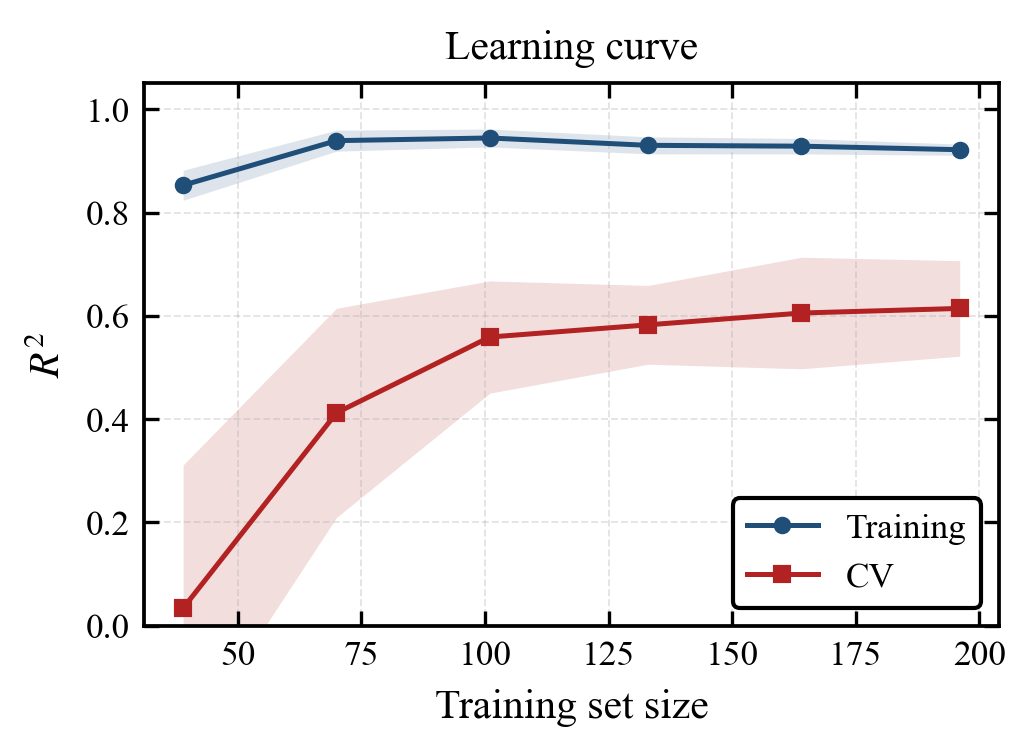

  Train R2: [0.853 0.939 0.944 0.93  0.928 0.922]
  CV R2:    [0.034 0.412 0.559 0.583 0.605 0.614]


In [19]:
from sklearn.model_selection import learning_curve

key = "CatBoost__5-6T"
model = saved_models_field[key]
data = saved_data_field[key]

print(f"=== {key}: расчёт learning curve ===")

train_sizes_abs, train_scores, test_scores = learning_curve(
    clone(model),
    data["X_final"],
    data["y_model_clean"],
    cv=data["cv_clean_seed"],
    scoring="r2",
    train_sizes=np.linspace(0.2, 1.0, 6),
    n_jobs=-1,
    random_state=42
)

train_mean = train_scores.mean(axis=1)
train_std = train_scores.std(axis=1)
test_mean = test_scores.mean(axis=1)
test_std = test_scores.std(axis=1)

plot_learning_curve(
    train_sizes_abs,
    train_mean,
    test_mean,
    train_std,
    test_std
)

print(f"  Train R2: {np.round(train_mean, 3)}")
print(f"  CV R2:    {np.round(test_mean, 3)}")

# Отрисовка всех основных графиков

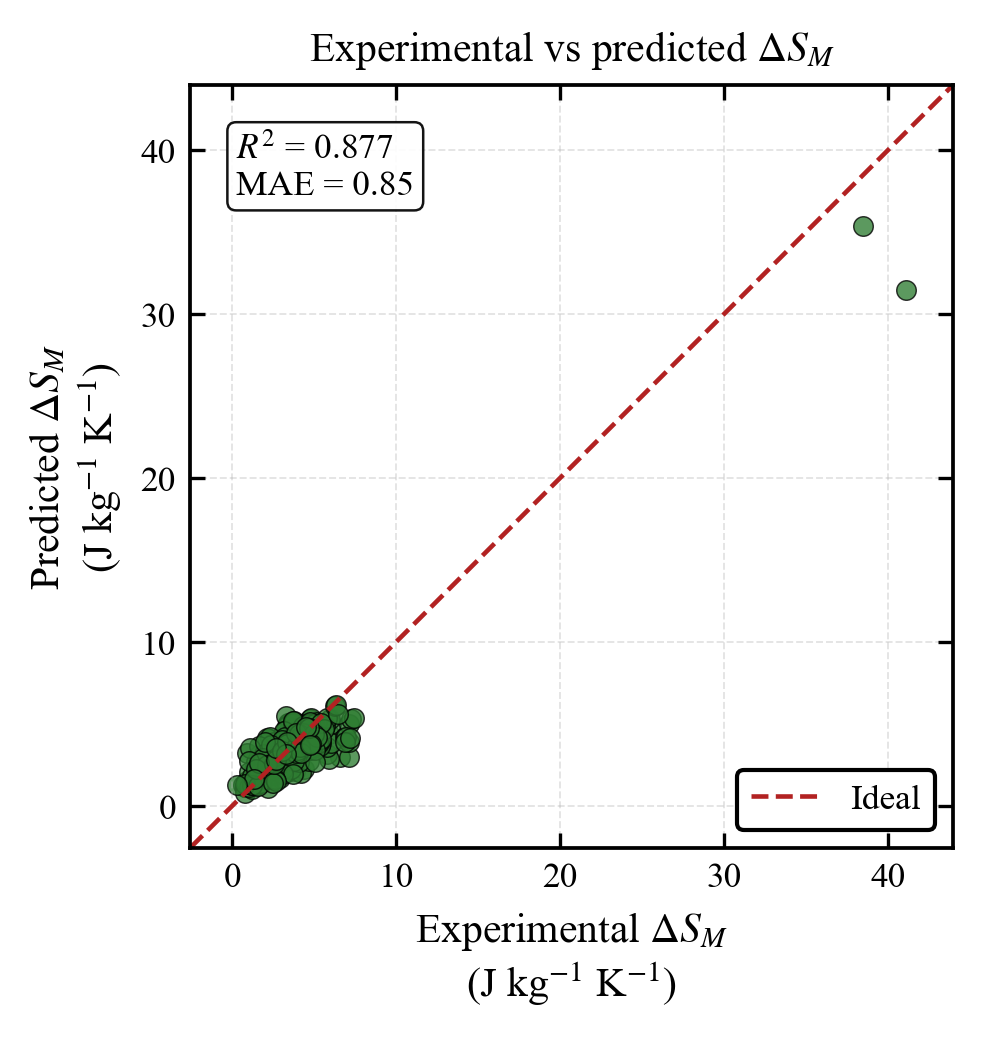

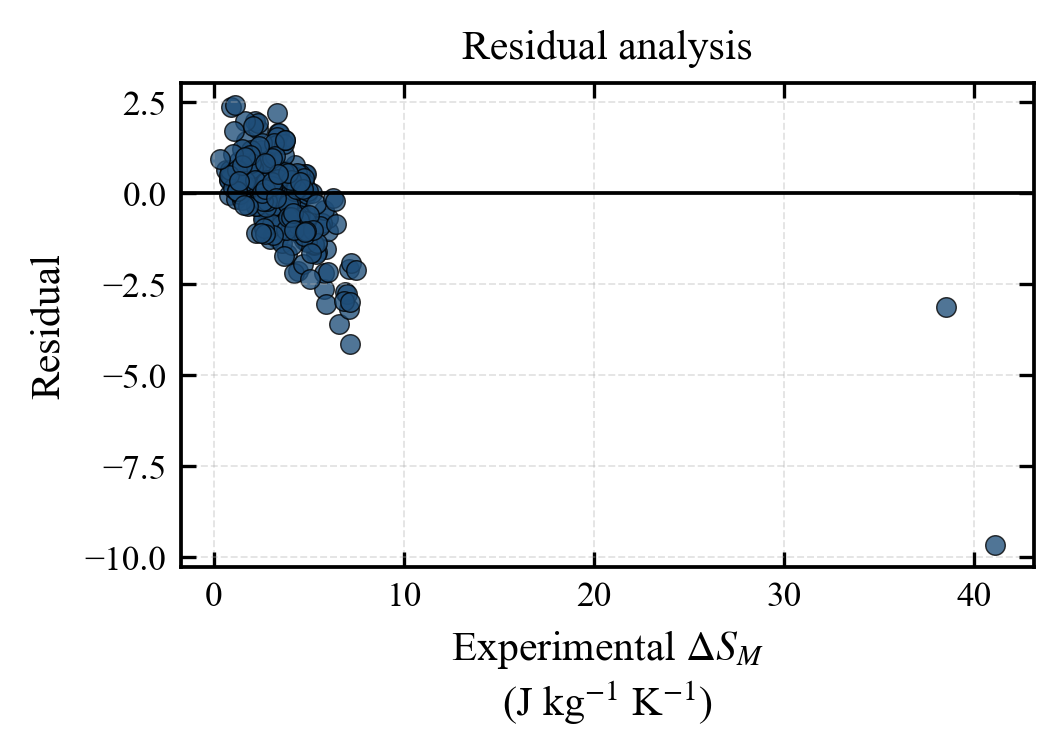

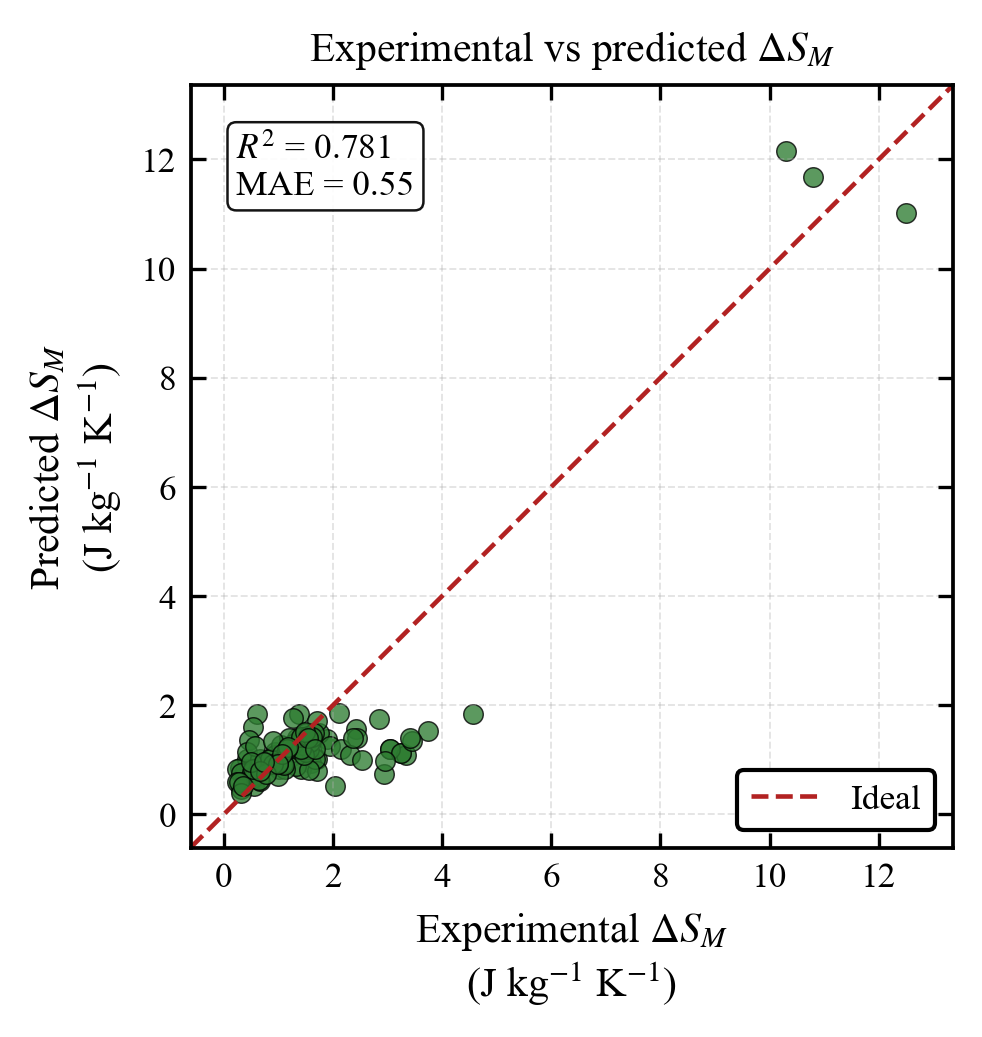

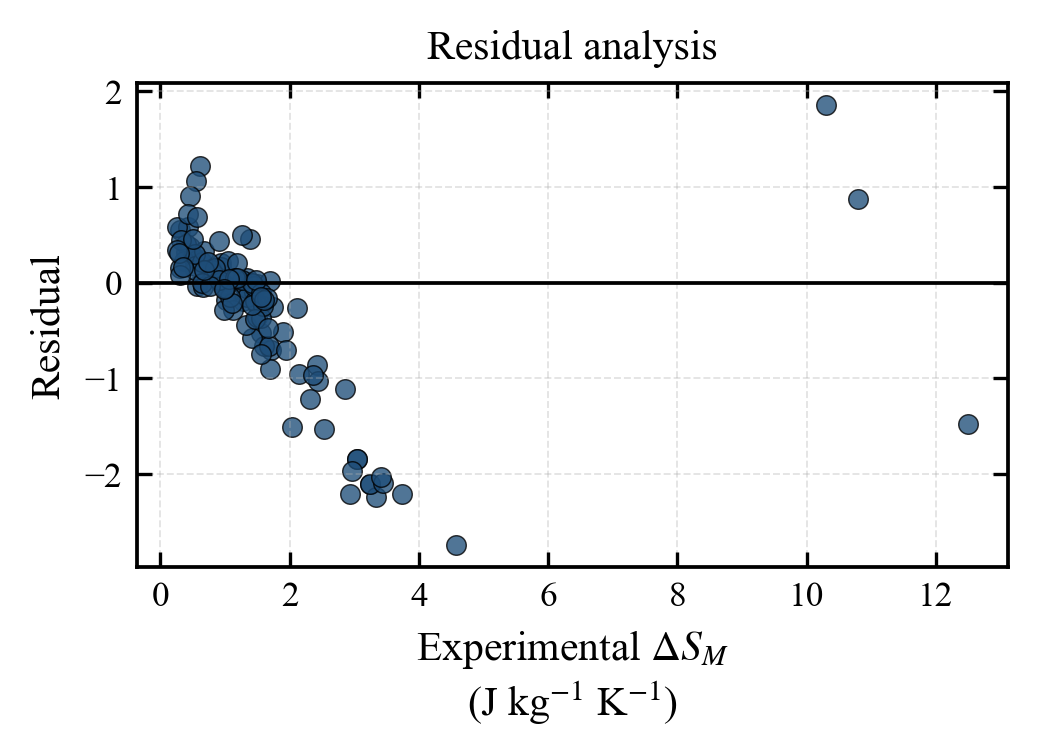

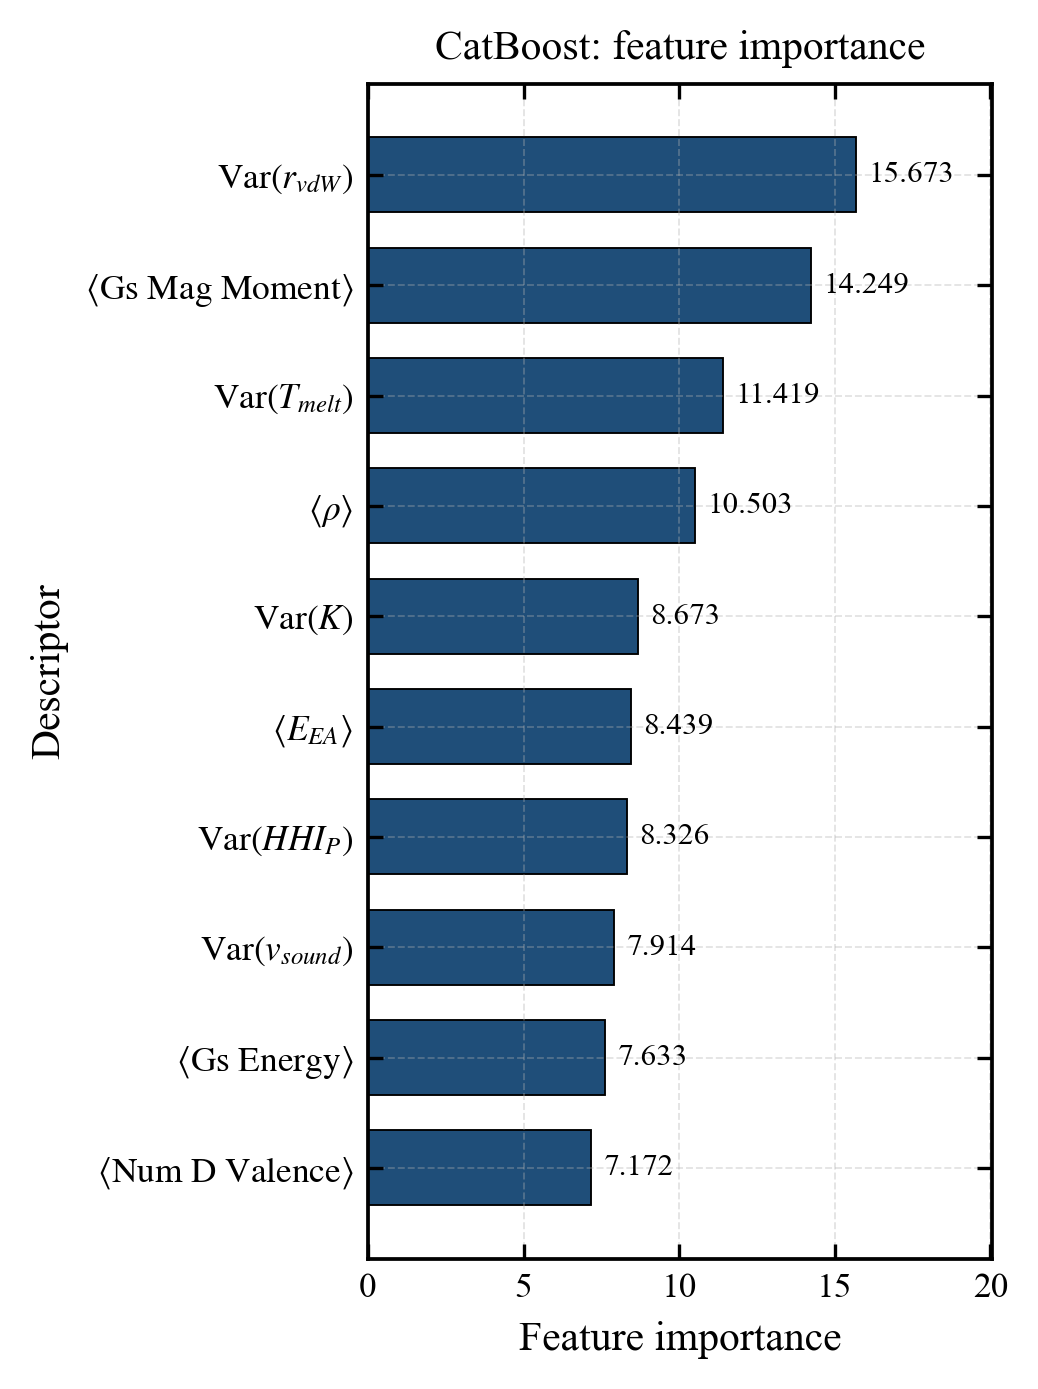

0               ave:density
1     ave:electron_affinity
2             ave:gs_energy
3         ave:gs_mag_moment
4         ave:num_d_valence
5          var:bulk_modulus
6                 var:hhi_p
7         var:melting_point
8    var:vdw_radius_alvarez
9        var:sound_velocity
Name: feature, dtype: str


In [23]:
# --- CatBoost, 5-6T (обучающие/CV данные, уже посчитаны в saved_data_field) ---
key = "CatBoost__5-6T"
data_5T = saved_data_field[key]

plot_parity(data_5T["y_orig_final"], data_5T["y_pred_final_orig"], name="catboost_5T")
plot_residuals(data_5T["y_orig_final"], data_5T["y_pred_final_orig"], name="catboost_5T")

# --- CatBoost, 1T (данные, скорректированные по n) ---
plot_parity(y_new_true[valid_mask].values, y_pred_1T_corrected[valid_mask], name="catboost_1T")
plot_residuals(y_new_true[valid_mask].values, y_pred_1T_corrected[valid_mask], name="catboost_1T")

key = "CatBoost__5-6T"
model = saved_models_field[key]
clean_info = clean_data_per_field_model[key]

feature_names = clean_info["feature_list_present"]
importances = model.feature_importances_

imp_df = pd.DataFrame({
    "feature": feature_names,
    "rf_importance": importances,
})

plot_feature_importance_paper(imp_df, model_name="CatBoost", orientation="horisontal")
print(imp_df["feature"])

# Сохранение финальных таблиц Excel

In [21]:
# Сохранение финальных таблиц Excel
dirty_summary_df.to_excel(os.path.join(out_dir, "model_metrics_dirty.xlsx"), index=False)
clean_summary_df.to_excel(os.path.join(out_dir, "model_metrics_clean.xlsx"), index=False)
optuna_results_df.to_excel(os.path.join(out_dir, "optuna_best_hyperparameters.xlsx"), index=False)

# Сохраняем важность признаков для каждой модели отдельно
with pd.ExcelWriter(os.path.join(out_dir, "feature_importance_all_models.xlsx")) as writer:
    for model_name in saved_models.keys():
        imp_series = get_importance(saved_models[model_name], saved_data[model_name]["feature_list_present"])
        if imp_series is not None:
            imp_df_export = pd.DataFrame({
                "feature": imp_series.index,
                "importance": imp_series.values
            }).sort_values("importance", ascending=False)
            imp_df_export.to_excel(writer, sheet_name=model_name[:31], index=False)

print(f"\nAll figures and tables saved to folder: {out_dir}")

NameError: name 'dirty_summary_df' is not defined